# Lunar NAC Crater Detection — SomBench Fresh Improved Pipeline

**Purpose:** train a fresh one-class crater detector on the public SomBench NAC Crater Detection dataset, choose its confidence threshold using validation only, and evaluate the held-out test split once using the benchmark's crater-centre/diameter matching rules.

## Fresh-run guarantee
- Starts from the public pretrained `yolo11n.pt` checkpoint; it does **not** load any previous crater checkpoint.
- Rebuilds the YOLO-format data from the downloaded SomBench source data.
- Uses only `standard` label-set images.
- Keeps the official train/validation/test partitions intact.
- Selects the confidence threshold on validation, then evaluates test once.

## Run instructions (Kaggle)
1. Create a new Kaggle notebook and enable **GPU** and **Internet** in Notebook settings.
2. Upload this `.ipynb` file or use it as the notebook itself.
3. Run cells from top to bottom. Do not skip the data audit or visual sanity-check cell.
4. If Kaggle reports an out-of-memory error, change `BATCH` from `16` to `8` in the configuration cell and restart from the training cell.
5. Download the final checkpoint and report files from `/kaggle/working/crater_yolo_work/` before the session ends, or save them as a Kaggle notebook output.

## Pipeline
1. Install dependencies and download SomBench.
2. Audit annotations and source image metadata.
3. Convert `standard` images and COCO boxes to YOLO format.
4. Train a fresh YOLO11n model with conservative augmentation and early stopping.
5. Select confidence on validation using custom SomBench matching.
6. Freeze the model and threshold; evaluate test once.
7. Save metrics, training history, plots, and checkpoint.

**Important:** this is a controlled first experiment, not a guaranteed improvement. Compare its validation metrics with earlier runs only if those runs used the same data split and matching implementation. Do not choose settings based on the test result.


## 0. Runtime and configuration

Use a GPU runtime where possible. This experiment keeps the lightweight YOLO11n architecture and changes the training recipe conservatively: lower learning rate, milder scale/brightness augmentation, and reduced mosaic. The goal is to improve generalisation without increasing model capacity.


In [1]:
# Kaggle: Internet must be enabled for package/model/dataset downloads.
%pip -q install -U "ultralytics>=8.3.0" huggingface_hub pycocotools opencv-python-headless scipy pandas matplotlib tqdm

import os, json, math, random, shutil, warnings, platform
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.optimize import linear_sum_assignment
from huggingface_hub import snapshot_download
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
except Exception:
    torch = None

REPO_ID = "nasa-ibm-ai4science/Sombench-NAC-Crater-Detection"
# Fresh Kaggle sessions use /kaggle/working. Colab is supported as well.
if Path("/kaggle/working").exists():
    BASE = Path("/kaggle/working")
elif Path("/content").exists():
    BASE = Path("/content")
else:
    BASE = Path.cwd()

ROOT = BASE / "sombench_nac"
WORK = BASE / "crater_yolo_work_fresh_v2"
RUNS = BASE / "crater_yolo_runs_fresh_v2"
ROOT.mkdir(parents=True, exist_ok=True)
WORK.mkdir(parents=True, exist_ok=True)
RUNS.mkdir(parents=True, exist_ok=True)

# Independent experiment: start from official pretrained weights, never an old crater best.pt.
MODEL_NAME = "yolo11n.pt"
IMGSZ = 640
EPOCHS = 100
PATIENCE = 15
BATCH = 16
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0005
MIN_DIAMETER_M = 10.0
CONF_GRID = np.round(np.arange(0.05, 0.951, 0.025), 3)

print("Runtime base:", BASE)
print("Dataset:", ROOT)
print("Work/output:", WORK)
print("Training runs:", RUNS)
print("GPU available:", bool(torch and torch.cuda.is_available()))
if torch and torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.1.1 which is incompatible.
ydata-profiling 4.18.4 requires scipy<1.17,>=1.8, but you have scipy 1.18.1 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
datasets 4.8.5 requires hug

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Runtime base: /kaggle/working
Dataset: /kaggle/working/sombench_nac
Work/output: /kaggle/working/crater_yolo_work_fresh_v2
Training runs: /kaggle/working/crater_yolo_runs_fresh_v2
GPU available: True
GPU: Tesla T4


## 1. Download the dataset

In [2]:
# Download into the current runtime. If the folder already contains the dataset, reuse it.
if not any(ROOT.iterdir()):
    snapshot_download(repo_id=REPO_ID, repo_type="dataset", local_dir=str(ROOT))
else:
    print("Dataset directory is not empty; reusing the existing downloaded dataset.")

for p in list(ROOT.iterdir())[:30]:
    print(p.name, "[dir]" if p.is_dir() else f"[{p.stat().st_size:,} bytes]")

required = [f"annotations_min5px_{s}.json" for s in ("train", "val", "test")]
missing = [name for name in required if not list(ROOT.rglob(name))]
if missing:
    raise FileNotFoundError(f"Missing expected annotation files: {missing}")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 426 files:   0%|          | 0/426 [00:00<?, ?it/s]

annotations.json [13,799,175 bytes]
README.md [6,280 bytes]
annotations_min5px_test.json [1,717,054 bytes]
annotations_min5px_train.json [10,266,959 bytes]
annotations_test.json [2,264,701 bytes]
annotations_train.json [14,079,216 bytes]
crater_catalog.parquet [2,851,284 bytes]
annotations_min5px.json [10,168,860 bytes]
.gitattributes [2,616 bytes]
.cache [dir]
annotations_min5px_val.json [1,424,316 bytes]
.DS_Store [6,148 bytes]
images [dir]
splits.json [1,842 bytes]
annotations_val.json [1,928,189 bytes]
previews [dir]


## 2. Locate annotations and inspect the dataset

The notebook deliberately discovers the annotation JSON and image files rather than assuming a fixed nested folder layout. Review the audit tables before continuing.

In [3]:
def find_annotation(split):
    target = f"annotations_min5px_{split}.json"
    matches = list(ROOT.rglob(target))
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected exactly one {target}; found: {matches}")
    return matches[0]

ANN_PATHS = {s: find_annotation(s) for s in ("train", "val", "test")}
COCO = {s: json.loads(p.read_text()) for s,p in ANN_PATHS.items()}

for split, data in COCO.items():
    print(f"\n--- {split.upper()} ---")
    print("images:", len(data.get("images", [])), "annotations:", len(data.get("annotations", [])))
    print("categories:", data.get("categories", []))
    print("image keys:", sorted(data["images"][0].keys()) if data.get("images") else [])
    print("annotation keys:", sorted(data["annotations"][0].keys()) if data.get("annotations") else [])

rows=[]
for split,data in COCO.items():
    counts=defaultdict(int)
    for im in data.get("images", []): counts[str(im.get("label_set", "MISSING"))]+=1
    for label_set,n in counts.items(): rows.append({"split":split,"label_set":label_set,"images":n})
label_audit=pd.DataFrame(rows)
display(label_audit)

# The supplied guide specifies that standard images are exhaustively labelled down to the dataset's minimum box size.
# 'large' images omit small craters and must not be mixed into the standard training target.
for split,data in COCO.items():
    sets={str(im.get("label_set", "MISSING")) for im in data.get("images", [])}
    if "standard" not in sets:
        raise ValueError(f"No standard-labelled images found in {split}: {sets}")
    if "MISSING" in sets:
        warnings.warn(f"Some {split} images lack label_set metadata; inspect before proceeding.")

# Find the actual .npy file corresponding to each COCO file_name.
NPY_FILES = list(ROOT.rglob("*.npy"))
if not NPY_FILES: raise FileNotFoundError("No .npy image tiles found under ROOT")
BY_NAME = defaultdict(list)
for p in NPY_FILES: BY_NAME[p.name].append(p)

def resolve_image(file_name):
    name=Path(file_name).name
    candidates=BY_NAME.get(name, [])
    if len(candidates)==1: return candidates[0]
    # Some releases may store a relative path under an images folder.
    exact=[p for p in NPY_FILES if p.as_posix().endswith(str(file_name).replace('\\','/'))]
    if len(exact)==1: return exact[0]
    if not candidates and not exact: raise FileNotFoundError(f"Cannot resolve image {file_name}")
    raise RuntimeError(f"Ambiguous image path for {file_name}: {candidates or exact}")

# Validate a sample image and image dimensions.
sample=COCO['train']['images'][0]
sample_path=resolve_image(sample['file_name'])
sample_arr=np.load(sample_path, allow_pickle=False)
print("Sample:", sample['file_name'], "->", sample_path, "shape:", sample_arr.shape, "dtype:", sample_arr.dtype)
print("Sample metadata:", {k:sample.get(k) for k in ('site','label_set','native_resolution_m','effective_resolution_m','nodata')})



--- TRAIN ---
images: 289 annotations: 29033
categories: [{'id': 1, 'name': 'crater'}]
image keys: ['box_no', 'dtype', 'effective_resolution_m', 'file_name', 'geotransform', 'height', 'id', 'label_set', 'native_resolution_m', 'nodata', 'site', 'source_image', 'split', 'upscale_factor', 'width']
annotation keys: ['area', 'bbox', 'category_id', 'diam_m', 'diam_px', 'id', 'image_id', 'iscrowd', 'src_file', 'truncated']

--- VAL ---
images: 56 annotations: 5830
categories: [{'id': 1, 'name': 'crater'}]
image keys: ['box_no', 'dtype', 'effective_resolution_m', 'file_name', 'geotransform', 'height', 'id', 'label_set', 'native_resolution_m', 'nodata', 'site', 'source_image', 'split', 'upscale_factor', 'width']
annotation keys: ['area', 'bbox', 'category_id', 'diam_m', 'diam_px', 'id', 'image_id', 'iscrowd', 'src_file', 'truncated']

--- TEST ---
images: 63 annotations: 7061
categories: [{'id': 1, 'name': 'crater'}]
image keys: ['box_no', 'dtype', 'effective_resolution_m', 'file_name', 'geotr

,split,label_set,images
0,train,standard,219
1,train,large,70
2,val,standard,52
3,val,large,4
4,test,large,17
5,test,standard,46


Sample: images/NAC_DTM_A15SIVB_PHO_E009S3481__standard_box1__r0_c0.npy -> /kaggle/working/sombench_nac/images/NAC_DTM_A15SIVB_PHO_E009S3481__standard_box1__r0_c0.npy shape: (256, 256) dtype: uint8
Sample metadata: {'site': 'NAC_DTM_A15SIVB_PHO_E009S3481', 'label_set': 'standard', 'native_resolution_m': 4.9999999999999005, 'effective_resolution_m': 4.00390624999992, 'nodata': 0.0}


## 3. Build the YOLO dataset

Each tile is contrast-stretched independently using its valid pixels’ 2nd–98th percentiles. The same conversion function is used later for inference. COCO boxes are converted to normalized YOLO centre-width-height format. The single crater category is mapped to class `0`.

In [4]:
YOLO_ROOT = WORK / "sombench_yolo"
for sub in ("images/train","images/val","labels/train","labels/val"):
    (YOLO_ROOT/sub).mkdir(parents=True, exist_ok=True)


def load_dn(path):
    arr=np.load(path, allow_pickle=False)
    if isinstance(arr, np.lib.npyio.NpzFile):
        keys=list(arr.keys())
        if len(keys)!=1: raise ValueError(f"Expected one array in NPZ {path}, found {keys}")
        arr=arr[keys[0]]
    arr=np.asarray(arr)
    if arr.ndim==3 and arr.shape[0]==1: arr=arr[0]
    if arr.ndim==3 and arr.shape[-1]==1: arr=arr[...,0]
    if arr.ndim!=2: raise ValueError(f"Expected 2D grayscale tile, got {arr.shape} at {path}")
    return arr


def valid_pixel_mask(arr, nodata=None):
    mask=np.isfinite(arr)
    if nodata is not None:
        try:
            if np.isnan(float(nodata)): mask &= np.isfinite(arr)
            else: mask &= (arr != float(nodata))
        except Exception: pass
    return mask


def stretch_dn(arr, nodata=None, lo=2, hi=98):
    arr=np.asarray(arr)
    mask=valid_pixel_mask(arr, nodata)
    out=np.zeros(arr.shape, dtype=np.uint8)
    if mask.sum()<10: return out
    vals=arr[mask].astype(np.float32)
    a,b=np.percentile(vals,[lo,hi])
    if not np.isfinite(a+b) or b<=a:
        a,b=float(vals.min()),float(vals.max())
    if b<=a: out[mask]=127
    else: out[mask]=np.clip((arr[mask].astype(np.float32)-a)*255.0/(b-a),0,255).astype(np.uint8)
    return out


def image_resolution_m(im):
    # Effective resolution should be used when present; native is fallback.
    value=im.get("effective_resolution_m", None)
    if value is None: value=im.get("native_resolution_m", None)
    if isinstance(value, (list,tuple)): value=value[0]
    if value is None or not np.isfinite(float(value)) or float(value)<=0:
        raise ValueError(f"Missing/invalid pixel resolution for image_id={im.get('id')}: {value}")
    return float(value)


def coco_annotations_by_image(data):
    out=defaultdict(list)
    for ann in data.get("annotations", []):
        if ann.get("iscrowd",0): continue
        out[ann["image_id"]].append(ann)
    return out


def safe_stem(im, split, index):
    # Stable, unique filenames even if source file names repeat across splits.
    return f"{split}_{index:05d}_{Path(im['file_name']).stem}"


def convert_split(split):
    data=COCO[split]
    ann_by_img=coco_annotations_by_image(data)
    selected=[(i,im) for i,im in enumerate(data["images"]) if im.get("label_set")=="standard"]
    if not selected: raise ValueError(f"No standard images in {split}")
    records=[]
    for index,im in tqdm(selected, desc=f"Convert {split}"):
        src=resolve_image(im["file_name"])
        dn=load_dn(src)
        h,w=dn.shape
        if "width" in im and int(im["width"])!=w: raise ValueError(f"Width mismatch for {im['file_name']}")
        if "height" in im and int(im["height"])!=h: raise ValueError(f"Height mismatch for {im['file_name']}")
        png=stretch_dn(dn, im.get("nodata"))
        stem=safe_stem(im,split,index)
        image_out=YOLO_ROOT/f"images/{split}/{stem}.png"
        label_out=YOLO_ROOT/f"labels/{split}/{stem}.txt"
        if not cv2.imwrite(str(image_out), png): raise IOError(f"Could not write {image_out}")
        lines=[]
        for ann in ann_by_img.get(im["id"], []):
            x,y,bw,bh=map(float,ann["bbox"])
            # Clip to image bounds and discard degenerate boxes.
            x0=max(0.0,x); y0=max(0.0,y); x1=min(float(w),x+bw); y1=min(float(h),y+bh)
            bw2=x1-x0; bh2=y1-y0
            if bw2<=0 or bh2<=0: continue
            cx=(x0+x1)/2/w; cy=(y0+y1)/2/h
            lines.append(f"0 {cx:.8f} {cy:.8f} {bw2/w:.8f} {bh2/h:.8f}")
        label_out.write_text("\n".join(lines))
        records.append({"split":split,"image_id":im["id"],"file_name":im["file_name"],"image_path":str(image_out),"source_path":str(src),"width":w,"height":h,"resolution_m":image_resolution_m(im),"site":im.get("site","unknown"),"label_set":im.get("label_set"),"nodata":im.get("nodata"),"n_annotations":len(lines)})
    return records

train_records=convert_split("train")
val_records=convert_split("val")
records_by_split={"train":train_records,"val":val_records}

# Dataset YAML for Ultralytics.
data_yaml=YOLO_ROOT/"data.yaml"
data_yaml.write_text("\n".join([
    f"path: {YOLO_ROOT}",
    "train: images/train",
    "val: images/val",
    "names:",
    "  0: crater",
    "nc: 1",
]))

for split,recs in records_by_split.items():
    print(split, "images:",len(recs),"boxes:",sum(r['n_annotations'] for r in recs))
    display(pd.DataFrame(recs).groupby("site",dropna=False).agg(images=("image_id","count"),boxes=("n_annotations","sum")))


Convert train:   0%|          | 0/219 [00:00<?, ?it/s]

Convert val:   0%|          | 0/52 [00:00<?, ?it/s]

train images: 219 boxes: 27182


,images,boxes
site,,
NAC_DTM_A15SIVB_PHO_E009S3481,3,991
NAC_DTM_Apollo17_PHO_E199N0308,75,8505
NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,57,6488
NAC_DTM_KINGEJECTA_PHO_E041N1229,61,9461
NAC_DTM_MARCH17_PHO_E207N3357,3,1076
NAC_DTM_REINER_PHO_E074N3010,20,661


val images: 52 boxes: 5482


,images,boxes
site,,
NAC_DTM_A15SIVB_PHO_E009S3481,1,187
NAC_DTM_Apollo17_PHO_E199N0308,25,2559
NAC_DTM_KINGEJECTA_PHO_E041N1229,25,2237
NAC_DTM_MARCH17_PHO_E207N3357,1,499


## 4. Visual sanity checks

Check that image contrast, annotation geometry, and category mapping look correct before training. If boxes are misplaced or images appear blank, stop and fix the conversion rather than training on corrupted data.

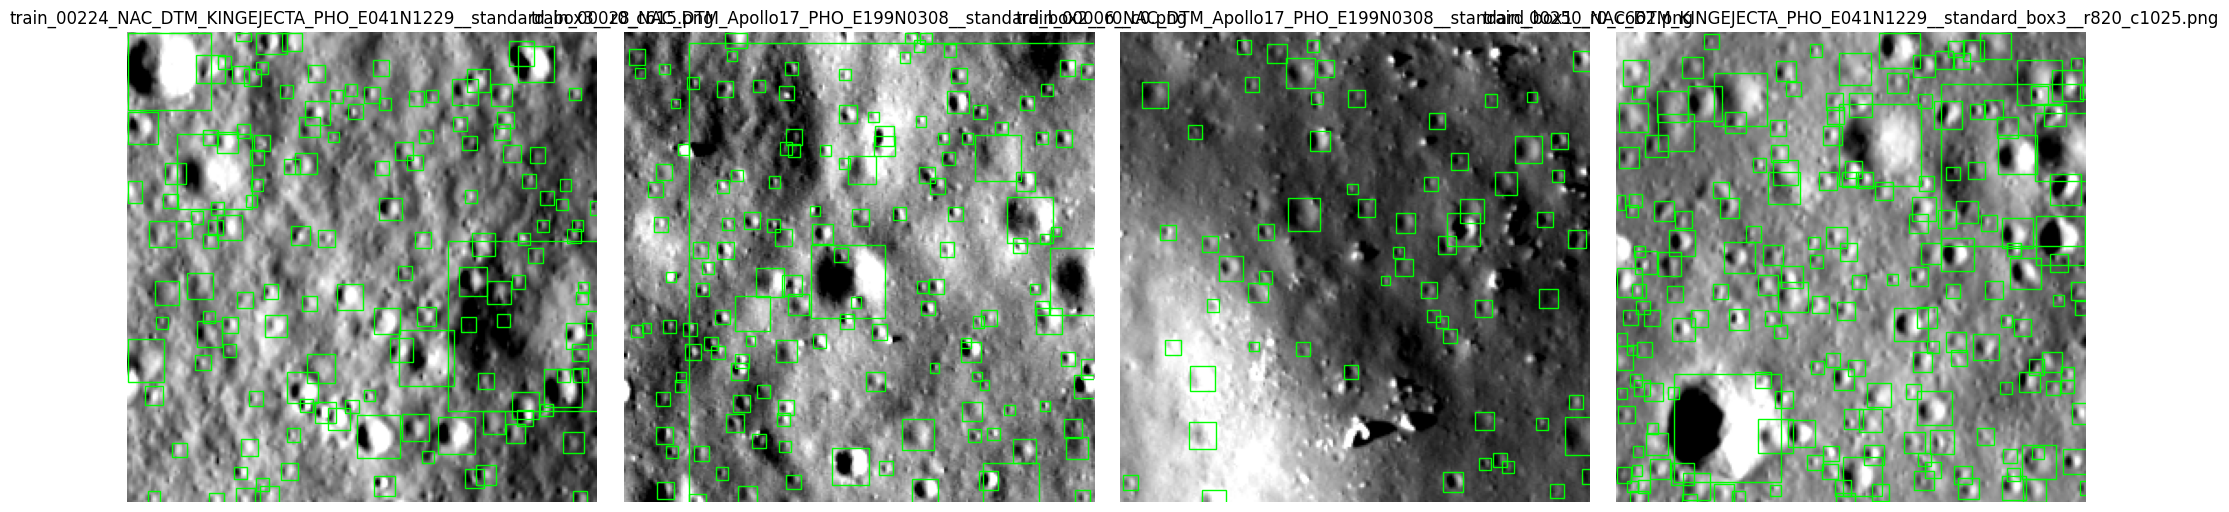

In [5]:
def show_yolo_sample(split="train", n=4):
    files=sorted((YOLO_ROOT/f"images/{split}").glob("*.png"))
    if not files: raise RuntimeError(f"No converted {split} images")
    chosen=random.sample(files,min(n,len(files)))
    fig,axes=plt.subplots(1,len(chosen),figsize=(5*len(chosen),5))
    if len(chosen)==1: axes=[axes]
    for ax,p in zip(axes,chosen):
        im=cv2.imread(str(p),cv2.IMREAD_GRAYSCALE)
        ax.imshow(im,cmap="gray")
        lab=YOLO_ROOT/f"labels/{split}/{p.stem}.txt"
        if lab.exists():
            for line in lab.read_text().splitlines():
                cls,cx,cy,bw,bh=map(float,line.split())
                h,w=im.shape; x=(cx-bw/2)*w; y=(cy-bh/2)*h
                ax.add_patch(plt.Rectangle((x,y),bw*w,bh*h,fill=False,edgecolor="lime",linewidth=1))
        ax.set_title(p.name); ax.axis("off")
    plt.tight_layout(); plt.show()

show_yolo_sample("train",4)


## 5. Train a fresh one-class YOLO model

This cell deliberately initializes from the public pretrained YOLO11n weights. It does not load any previous crater-specific checkpoint. The revised settings are intentionally conservative for a small dataset: `lr0=0.001`, `scale=0.15`, `hsv_v=0.15`, and `mosaic=0.3`, with early stopping.


In [6]:
# FRESH TRAINING: do not replace MODEL_NAME with an earlier crater checkpoint.
model = YOLO(MODEL_NAME)

train_results = model.train(
    data=str(data_yaml),
    imgsz=IMGSZ,
    epochs=EPOCHS,
    patience=PATIENCE,
    batch=BATCH,
    single_cls=True,

    # Conservative optimisation for a small labelled dataset
    optimizer="AdamW",
    lr0=LEARNING_RATE,
    lrf=0.01,
    weight_decay=WEIGHT_DECAY,

    # Geometry: crater detection is orientation-independent
    fliplr=0.5,
    flipud=0.5,
    degrees=0.0,
    scale=0.15,

    # NAC tiles are grayscale; disable hue/saturation changes
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.15,

    # Reduce synthetic composition intensity
    mosaic=0.3,
    close_mosaic=10,

    seed=SEED,
    deterministic=True,
    project=str(RUNS),
    name="sombench_yolo11n_controlled_fresh_v2",
    exist_ok=False,
    plots=True,
    workers=2,
    device=0 if (torch and torch.cuda.is_available()) else "cpu",
)

BEST_WEIGHTS = Path(model.trainer.best).resolve()
if not BEST_WEIGHTS.exists():
    raise FileNotFoundError(f"Best checkpoint not found: {BEST_WEIGHTS}")

# Keep a separate copy in WORK so it is easy to find/download from Kaggle.
CHECKPOINT_COPY = WORK / "best_crater_model_fresh_v2.pt"
shutil.copy2(BEST_WEIGHTS, CHECKPOINT_COPY)
print("Best checkpoint:", BEST_WEIGHTS)
print("Portable copy:", CHECKPOINT_COPY)
print("Checkpoint size (MB):", round(CHECKPOINT_COPY.stat().st_size / 1024**2, 2))


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/crater_yolo_work_fresh_v2/sombench_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.15, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.3, multi_scale=0.0, name=sombench_yolo11n_cont

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      5.28G      2.071      1.365      1.224       1304        640: 100% ━━━━━━━━━━━━ 14/14 7.3it/s 1.9s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.3it/s 0.9s1.7s
                   all         52       5482      0.425      0.467      0.402      0.144

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      5.28G      1.982      1.244      1.174       1150        640: 100% ━━━━━━━━━━━━ 14/14 7.4it/s 1.9s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.3it/s 0.9s1.8s
                   all         52       5482      0.495       0.51      0.461      0.181

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/100      5.28G      1.947      1.194      1.152       1324        640: 100% ━━━━━━━━━━━━ 14/14 7.3it/s 1.9s0.1s
                 Class     Images  Instances  

## 6. Crater-specific matching and validation threshold selection

A predicted crater matches a labelled crater when its centre is within half the labelled diameter and its relative diameter error is at most 50%. Use Hungarian assignment for one-to-one matching. Ground-truth craters below 10 m are ignored; predictions that overlap/centre-match those ignored labels are “don’t care” rather than false positives. All other unmatched predictions are false positives.

In [7]:
def coco_gt_for_image(split, image_id):
    data=COCO[split]
    im=next(x for x in data["images"] if x["id"]==image_id)
    anns=[a for a in data.get("annotations",[]) if a["image_id"]==image_id and not a.get("iscrowd",0)]
    gt=[]
    for a in anns:
        x,y,w,h=map(float,a["bbox"])
        # COCO box diameter approximation: mean of width and height in pixels.
        d_px=(w+h)/2.0
        gt.append({"cx":x+w/2,"cy":y+h/2,"diam_px":d_px,"diam_m":d_px*image_resolution_m(im)})
    return im,gt


def get_predictions(model, record, conf=0.001, imgsz=640, transform="baseline"):
    image=cv2.imread(record["image_path"],cv2.IMREAD_GRAYSCALE)
    if image is None: raise IOError(record["image_path"])
    if transform=="clahe":
        image=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(image)
    elif transform!="baseline":
        raise ValueError("Unknown transform")
    # Ultralytics accepts a numpy image; grayscale is expanded to 3-channel for consistent model input.
    rgb=cv2.cvtColor(image,cv2.COLOR_GRAY2RGB)
    result=model.predict(source=rgb,conf=conf,imgsz=imgsz,max_det=3000,verbose=False)[0]
    preds=[]
    if result.boxes is not None:
        for b in result.boxes:
            x1,y1,x2,y2=map(float,b.xyxy[0].cpu().numpy())
            preds.append({"cx":(x1+x2)/2,"cy":(y1+y2)/2,"diam_px":((x2-x1)+(y2-y1))/2,"conf":float(b.conf[0].cpu())})
    return preds


def match_one_image(preds, gt, resolution_m, min_diameter_m=10.0):
    scored=[g for g in gt if g["diam_m"]>=min_diameter_m]
    ignored=[g for g in gt if g["diam_m"]<min_diameter_m]
    if scored and preds:
        cost=np.full((len(scored),len(preds)),1e6,dtype=float)
        valid=np.zeros_like(cost,dtype=bool)
        for i,g in enumerate(scored):
            for j,p in enumerate(preds):
                dist=math.hypot(p["cx"]-g["cx"],p["cy"]-g["cy"])
                rel=abs(p["diam_px"]-g["diam_px"])/max(g["diam_px"],1e-9)
                if dist<=0.5*g["diam_px"] and rel<=0.5:
                    valid[i,j]=True
                    # Prefer closer centres and more accurate diameter among valid pairs.
                    cost[i,j]=dist/max(0.5*g["diam_px"],1e-9)+rel
        ri,ci=linear_sum_assignment(cost)
        matches=[(i,j) for i,j in zip(ri,ci) if valid[i,j]]
    else:
        matches=[]
    matched_pred={j for _,j in matches}
    # Predictions that correspond to a <10m labelled crater are ignored (not FP).
    ignored_pred=set()
    for j,p in enumerate(preds):
        if j in matched_pred: continue
        for g in ignored:
            dist=math.hypot(p["cx"]-g["cx"],p["cy"]-g["cy"])
            rel=abs(p["diam_px"]-g["diam_px"])/max(g["diam_px"],1e-9)
            if dist<=0.5*g["diam_px"] and rel<=0.5:
                ignored_pred.add(j); break
    tp=len(matches); fn=len(scored)-tp; fp=len(preds)-len(matched_pred)-len(ignored_pred)
    ratios=[preds[j]["diam_px"]/scored[i]["diam_px"] for i,j in matches]
    return {"tp":tp,"fp":fp,"fn":fn,"n_scored_gt":len(scored),"n_ignored_gt":len(ignored),"n_ignored_pred":len(ignored_pred),"diameter_ratios":ratios}


def evaluate_records(model, split, records, conf, transform="baseline", prediction_cache=None):
    rows=[]; all_ratios=[]
    for rec in tqdm(records,desc=f"Evaluate {split} conf={conf}"):
        _,gt=coco_gt_for_image(split,rec["image_id"])
        if prediction_cache is None:
            preds=get_predictions(model,rec,conf=conf,transform=transform)
        else:
            preds=[p for p in prediction_cache[rec["image_id"]] if p["conf"]>=conf]
        m=match_one_image(preds,gt,rec["resolution_m"],MIN_DIAMETER_M)
        tp,fp,fn=m["tp"],m["fp"],m["fn"]
        precision=tp/(tp+fp) if tp+fp else 0.0
        recall=tp/(tp+fn) if tp+fn else 0.0
        f1=2*precision*recall/(precision+recall) if precision+recall else 0.0
        rows.append({"image_id":rec["image_id"],"file_name":rec["file_name"],"site":rec["site"],"resolution_m":rec["resolution_m"],"tp":tp,"fp":fp,"fn":fn,"precision":precision,"recall":recall,"f1":f1,"n_scored_gt":m["n_scored_gt"],"n_ignored_gt":m["n_ignored_gt"],"n_ignored_pred":m["n_ignored_pred"],"diameter_ratios":m["diameter_ratios"]})
        all_ratios.extend(m["diameter_ratios"])
    df=pd.DataFrame(rows)
    TP,FP,FN=df.tp.sum(),df.fp.sum(),df.fn.sum()
    P=TP/(TP+FP) if TP+FP else 0.0
    R=TP/(TP+FN) if TP+FN else 0.0
    F=2*P*R/(P+R) if P+R else 0.0
    summary={"split":split,"confidence":conf,"transform":transform,"TP":int(TP),"FP":int(FP),"FN":int(FN),"precision":P,"recall":R,"F1":F,"median_detected_to_labelled_diameter_ratio":float(np.median(all_ratios)) if all_ratios else np.nan,"images":len(df)}
    return df,summary

val_records_eval=[]
for r in val_records:
    # retain the COCO image_id mapping and corresponding converted image path
    val_records_eval.append(r)

val_model=YOLO(str(BEST_WEIGHTS))
print("Caching validation predictions once at low confidence for the threshold sweep...")
val_prediction_cache={r["image_id"]:get_predictions(val_model,r,conf=0.001,transform="baseline") for r in tqdm(val_records_eval,desc="Cache validation predictions")}
threshold_rows=[]
for conf in CONF_GRID:
    _,s=evaluate_records(val_model,"val",val_records_eval,float(conf),transform="baseline",prediction_cache=val_prediction_cache)
    threshold_rows.append(s)
threshold_df=pd.DataFrame(threshold_rows)
display(threshold_df.sort_values(["F1","precision"],ascending=False).head(10))

# Deterministic tie-break: highest F1, then highest precision, then higher threshold.
best_val=threshold_df.sort_values(["F1","precision","confidence"],ascending=[False,False,False]).iloc[0]
BEST_CONF=float(best_val["confidence"])
print("Selected validation confidence threshold:",BEST_CONF)
threshold_df.to_csv(WORK/"validation_threshold_sweep.csv",index=False)


Caching validation predictions once at low confidence for the threshold sweep...


Cache validation predictions:   0%|          | 0/52 [00:00<?, ?it/s]

Evaluate val conf=0.05:   0%|          | 0/52 [00:00<?, ?it/s]

Evaluate val conf=0.075:   0%|          | 0/52 [00:00<?, ?it/s]

Evaluate val conf=0.1:   0%|          | 0/52 [00:00<?, ?it/s]

Evaluate val conf=0.125:   0%|          | 0/52 [00:00<?, ?it/s]

... (31 outputs left out)

Evaluate val conf=0.925:   0%|          | 0/52 [00:00<?, ?it/s]

Evaluate val conf=0.95:   0%|          | 0/52 [00:00<?, ?it/s]

,split,confidence,transform,TP,FP,FN,precision,recall,F1,median_detected_to_labelled_diameter_ratio,images
20,val,0.550,baseline,587,190,877,0.755470,0.400956,0.523873,1.001845,52
21,val,0.575,baseline,570,146,894,0.796089,0.389344,0.522936,1.002161,52
19,val,0.525,baseline,605,248,859,0.709261,0.413251,0.522227,1.002242,52
18,val,0.500,baseline,628,331,836,0.654849,0.428962,0.518366,1.001247,52
22,val,0.600,baseline,539,98,925,0.846154,0.368169,0.513089,1.003502,52
17,val,0.475,baseline,645,413,819,0.609641,0.440574,0.511499,1.001194,52
23,val,0.625,baseline,512,58,952,0.898246,0.349727,0.503441,1.002991,52
16,val,0.450,baseline,668,524,796,0.560403,0.456284,0.503012,1.001247,52
15,val,0.425,baseline,687,641,777,0.517319,0.469262,0.492120,0.999951,52
14,val,0.400,baseline,703,756,761,0.481837,0.480191,0.481013,0.999854,52


Selected validation confidence threshold: 0.55


## 7. Freeze configuration, then evaluate held-out test once

Do not use test results to alter the model, confidence threshold, preprocessing, or matching rules. If you make changes after this point, treat the test split as consumed and use a new independent benchmark for the next final estimate.

In [8]:
# Construct test records only now; do not use test for model/threshold selection.
test_records=[]
for index,im in enumerate(COCO["test"]["images"]):
    if im.get("label_set")!="standard": continue
    src=resolve_image(im["file_name"])
    dn=load_dn(src)
    stem=safe_stem(im,"test",index)
    image_out=YOLO_ROOT/f"images/test/{stem}.png"
    image_out.parent.mkdir(parents=True,exist_ok=True)
    cv2.imwrite(str(image_out),stretch_dn(dn,im.get("nodata")))
    test_records.append({"split":"test","image_id":im["id"],"file_name":im["file_name"],"image_path":str(image_out),"source_path":str(src),"width":dn.shape[1],"height":dn.shape[0],"resolution_m":image_resolution_m(im),"site":im.get("site","unknown"),"label_set":im.get("label_set"),"nodata":im.get("nodata")})

final_model=YOLO(str(BEST_WEIGHTS))
test_df,test_summary=evaluate_records(final_model,"test",test_records,BEST_CONF,transform="baseline")
print(json.dumps(test_summary,indent=2))
test_df.to_csv(WORK/"test_per_image_metrics.csv",index=False)
pd.DataFrame([test_summary]).to_csv(WORK/"test_summary.csv",index=False)


Evaluate test conf=0.55:   0%|          | 0/46 [00:00<?, ?it/s]

{
  "split": "test",
  "confidence": 0.55,
  "transform": "baseline",
  "TP": 678,
  "FP": 58,
  "FN": 903,
  "precision": 0.9211956521739131,
  "recall": 0.428842504743833,
  "F1": 0.5852395338800173,
  "median_detected_to_labelled_diameter_ratio": 0.9690944328067415,
  "images": 46
}


## 8. Per-image and size-bin reporting

Pooled precision/recall/F1 are computed from pooled TP/FP/FN counts. Per-image metrics are also retained to show variability across tiles/sites. Size-bin results use the labelled crater diameter in metres and the same one-to-one matching rule.

In [9]:
display(test_df[["file_name","site","resolution_m","tp","fp","fn","precision","recall","f1","n_scored_gt","n_ignored_gt"]].sort_values(["site","file_name"]))

# Per-site macro averages are descriptive; pooled counts remain the main aggregate.
site_report=test_df.groupby("site",dropna=False).agg(images=("image_id","count"),TP=("tp","sum"),FP=("fp","sum"),FN=("fn","sum"),mean_image_precision=("precision","mean"),mean_image_recall=("recall","mean"),mean_image_F1=("f1","mean")).reset_index()
display(site_report)

# Size-bin metrics require re-matching predictions against GT grouped by labelled size.
# Re-run inference once at the frozen threshold and assign each TP to its GT size bin.
def size_bin(d):
    if d<10: return "<10 m (ignore)"
    if d<20: return "10–20 m"
    if d<50: return "20–50 m"
    if d<100: return "50–100 m"
    return "≥100 m"

size_counts=defaultdict(lambda:{"gt":0,"tp":0})
for rec in tqdm(test_records,desc="Size-bin analysis"):
    _,gt=coco_gt_for_image("test",rec["image_id"])
    scored=[g for g in gt if g["diam_m"]>=MIN_DIAMETER_M]
    preds=get_predictions(final_model,rec,conf=BEST_CONF,transform="baseline")
    # Build valid match matrix, Hungarian assignment, then count matched GTs by their true size.
    if scored and preds:
        valid=np.zeros((len(scored),len(preds)),bool); cost=np.full(valid.shape,1e6)
        for i,g in enumerate(scored):
            for j,p in enumerate(preds):
                dist=math.hypot(p["cx"]-g["cx"],p["cy"]-g["cy"])
                rel=abs(p["diam_px"]-g["diam_px"])/max(g["diam_px"],1e-9)
                if dist<=0.5*g["diam_px"] and rel<=0.5:
                    valid[i,j]=True; cost[i,j]=dist/max(0.5*g["diam_px"],1e-9)+rel
        ri,ci=linear_sum_assignment(cost)
        matched={i for i,j in zip(ri,ci) if valid[i,j]}
    else: matched=set()
    for i,g in enumerate(scored):
        b=size_bin(g["diam_m"]); size_counts[b]["gt"]+=1
        if i in matched: size_counts[b]["tp"]+=1

size_rows=[]
for b,v in size_counts.items():
    size_rows.append({"size_bin":b,"labelled_craters":v["gt"],"detected":v["tp"],"recall":v["tp"]/v["gt"] if v["gt"] else np.nan})
size_report=pd.DataFrame(size_rows)
display(size_report)
size_report.to_csv(WORK/"test_size_bin_recall.csv",index=False)


,file_name,site,resolution_m,tp,fp,fn,precision,recall,f1,n_scored_gt,n_ignored_gt
0,images/NAC_DTM_HLNDPHOTOM2_PHO_E011N1499__stan...,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,1.100000,17,3,9,0.850000,0.653846,0.739130,26,80
1,images/NAC_DTM_HLNDPHOTOM2_PHO_E011N1499__stan...,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,1.100000,27,4,4,0.870968,0.870968,0.870968,31,58
2,images/NAC_DTM_HLNDPHOTOM2_PHO_E011N1499__stan...,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,1.100000,21,1,16,0.954545,0.567568,0.711864,37,100
3,images/NAC_DTM_HLNDPHOTOM2_PHO_E011N1499__stan...,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,1.100000,31,0,18,1.000000,0.632653,0.775000,49,97
4,images/NAC_DTM_HLNDPHOTOM2_PHO_E011N1499__stan...,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,1.100000,20,5,19,0.800000,0.512821,0.625000,39,86
5,images/NAC_DTM_HLNDPHOTOM2_PHO_E011N1499__stan...,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,1.100000,20,8,13,0.714286,0.606061,0.655738,33,111
6,images/NAC_DTM_HLNDPHOTOM2_PHO_E011N1499__stan...,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,1.100000,19,3,27,0.863636,0.413043,0.558824,46,95
7,images/NAC_DTM_HLNDPHOTOM2_PHO_E011N1499__stan...,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,1.100000,21,4,9,0.840000,0.700000,0.763636,30,82
8,images/NAC_DTM_HLNDPHOTOM2_PHO_E011N1499__stan...,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,1.100000,17,2,14,0.894737,0.548387,0.680000,31,79
9,images/NAC_DTM_HLNDPHOTOM2_PHO_E011N1499__stan...,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,1.100000,12,3,14,0.800000,0.461538,0.585366,26,70


,site,images,TP,FP,FN,mean_image_precision,mean_image_recall,mean_image_F1
0,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,16,306,40,224,0.886340,0.582717,0.696423
1,NAC_DTM_KINGEJECTA_PHO_E041N1229,25,312,16,218,0.945086,0.600587,0.727904
2,NAC_DTM_MARCH17_PHO_E207N3357,1,40,1,329,0.975610,0.108401,0.195122
3,NAC_DTM_REINER_PHO_E074N3010,4,20,1,132,0.964286,0.129650,0.226934


Size-bin analysis:   0%|          | 0/46 [00:00<?, ?it/s]

,size_bin,labelled_craters,detected,recall
0,20–50 m,544,136,0.250000
1,10–20 m,946,508,0.536998
2,50–100 m,49,20,0.408163
3,≥100 m,42,14,0.333333


## 9. Optional preprocessing ablation: CLAHE

Run only after the baseline model and test evaluation have been frozen and reported. This is an exploratory ablation, not a way to replace the primary test result. For a strict benchmark, choose preprocessing on validation first and then evaluate the chosen variant once on test.

In [10]:
# Optional: validation-only CLAHE threshold sweep using the same trained weights.
# Uncomment to investigate CLAHE. Do not compare multiple test variants and then report only the best.
# clahe_val=[]
# for conf in CONF_GRID:
#     _,s=evaluate_records(val_model,"val",val_records,float(conf),transform="clahe")
#     clahe_val.append(s)
# clahe_val_df=pd.DataFrame(clahe_val)
# display(clahe_val_df.sort_values(["F1","precision"],ascending=False).head())
# clahe_conf=float(clahe_val_df.sort_values(["F1","precision","confidence"],ascending=[False,False,False]).iloc[0]["confidence"])
# print("CLAHE validation-selected threshold:",clahe_conf)
# Only if you pre-register CLAHE as the chosen variant based on validation, run the corresponding test evaluation:
# clahe_test_df,clahe_test_summary=evaluate_records(final_model,"test",test_records,clahe_conf,transform="clahe")
# print(clahe_test_summary)


## 10. Save artifacts and create a reproducibility record

In [11]:
import ultralytics, scipy
repro = {
    "experiment": "fresh_controlled_yolo11n_v2",
    "dataset_repo": REPO_ID,
    "model_checkpoint": str(BEST_WEIGHTS),
    "model_name": MODEL_NAME,
    "imgsz": IMGSZ, "epochs_requested": EPOCHS, "patience": PATIENCE, "batch": BATCH,
    "optimizer": "AdamW", "lr0": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
    "augmentation": {"fliplr": 0.5, "flipud": 0.5, "degrees": 0.0, "scale": 0.15, "hsv_h": 0.0, "hsv_s": 0.0, "hsv_v": 0.15, "mosaic": 0.3, "close_mosaic": 10},
    "seed": SEED, "min_scored_diameter_m": MIN_DIAMETER_M,
    "selected_confidence_from_validation": BEST_CONF,
    "matching": "Hungarian one-to-one; centre distance <= 0.5 * labelled diameter; relative diameter error <= 0.5",
    "small_crater_policy": "GT below 10m are ignored; detections matching them are not counted as FP",
    "test_summary": test_summary,
    "python": platform.python_version(), "ultralytics": ultralytics.__version__, "scipy": scipy.__version__,
}
(WORK / "reproducibility.json").write_text(json.dumps(repro, indent=2, default=str))
print("Artifacts saved under:", WORK)
for p in sorted(WORK.glob("*")):
    print(p.name, p.stat().st_size if p.is_file() else "[dir]")


Artifacts saved under: /kaggle/working/crater_yolo_work_fresh_v2
best_crater_model_fresh_v2.pt 5505754
reproducibility.json 1322
sombench_yolo [dir]
test_per_image_metrics.csv 21503
test_size_bin_recall.csv 173
test_summary.csv 214
validation_threshold_sweep.csv 3979


## 11. Interpretation and limitations

- SomBench contains NAC tiles with long-shadow conditions; performance may degrade for high-Sun/low-shadow imagery. The benchmark does not by itself establish robustness across all illumination geometries.
- The test split is separated by 1 km study box, but it is not a fully independent geographic holdout from every training/validation site.
- Box-derived diameters are approximations; report the median predicted/labelled diameter ratio alongside detection metrics.
- Do not add a boulder filter unless you have a separately validated boulder dataset and demonstrate that it improves crater precision without harming recall. Boulder labels are not part of this one-class benchmark.
- A segmentation head is outside this notebook’s scope; SomBench annotations supplied here are boxes.
- The supplied pipeline guide’s optional private Apollo 12 / Chang’e-5 dataset is restricted. Keep it separate, do not train/tune on its held-out test labels, and do not redistribute it without permission.

## References and attribution

- Patil et al. (2026), **SomBench NAC Crater Detection**, Hugging Face dataset: https://huggingface.co/datasets/nasa-ibm-ai4science/Sombench-NAC-Crater-Detection (CC BY 4.0 as stated in the supplied dataset guide; cite the dataset and retain NASA/GSFC/ASU imagery credit).
- Fraccaro et al. (2026), paper introducing the NASA–IBM lunar foundation model, arXiv:2609.13283: https://arxiv.org/abs/2609.13283.
- Ultralytics documentation: https://docs.ultralytics.com/.

**Suggested report table:** model/checkpoint, input resolution, preprocessing, validation-selected confidence, pooled test precision/recall/F1, per-site recall, size-bin recall, median detected/labelled diameter ratio, and any deviations from the protocol.

## 12. Model analysis (uses the newly trained crater checkpoint)

This section loads `BEST_WEIGHTS` produced in Section 5. It does not load the generic COCO checkpoint or any previous crater model. The test metrics shown here are from this fresh run only.


In [12]:
# Load and verify the newly trained crater detector
analysis_model = YOLO(str(BEST_WEIGHTS))
names = analysis_model.names
class_names = list(names.values()) if isinstance(names, dict) else list(names)
print("Checkpoint:", BEST_WEIGHTS)
print("Model classes:", names)
print("Number of classes:", len(class_names))
if len(class_names) != 1:
    raise ValueError(f"Expected a one-class detector; found: {names}")
print("Verified: one-class model; training dataset maps class 0 to crater.")


Checkpoint: /kaggle/working/crater_yolo_runs_fresh_v2/sombench_yolo11n_controlled_fresh_v2/weights/best.pt
Model classes: {0: 'item'}
Number of classes: 1
Verified: one-class model; training dataset maps class 0 to crater.


### 12.1 Training convergence and validation curves

Epochs recorded: 50


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
45,46,147.285,1.72196,0.94410,1.04467,0.72013,0.64119,0.69499,0.31677,1.88473,1.10440,1.06621,0.000554,0.000554,0.000554
46,47,150.261,1.71787,0.93624,1.04169,0.74586,0.66454,0.72821,0.35652,1.75675,0.98127,1.02612,0.000545,0.000545,0.000545
47,48,153.235,1.70949,0.93840,1.04102,0.75675,0.66855,0.73746,0.36515,1.74729,0.96854,1.02705,0.000535,0.000535,0.000535
48,49,156.157,1.71389,0.94875,1.04101,0.76376,0.67111,0.74243,0.37997,1.70824,0.98972,1.01751,0.000525,0.000525,0.000525
49,50,159.129,1.72433,0.94136,1.03732,0.74319,0.67694,0.73372,0.35869,1.78276,1.03029,1.03544,0.000515,0.000515,0.000515


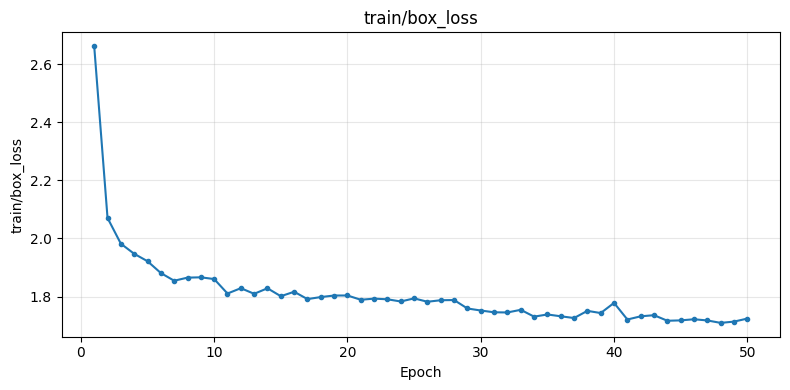

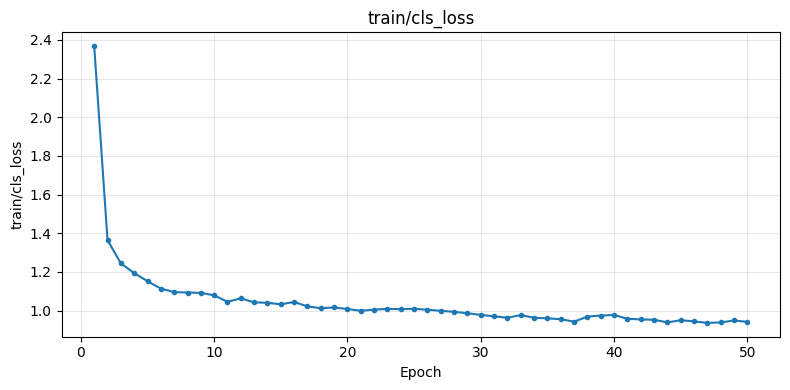

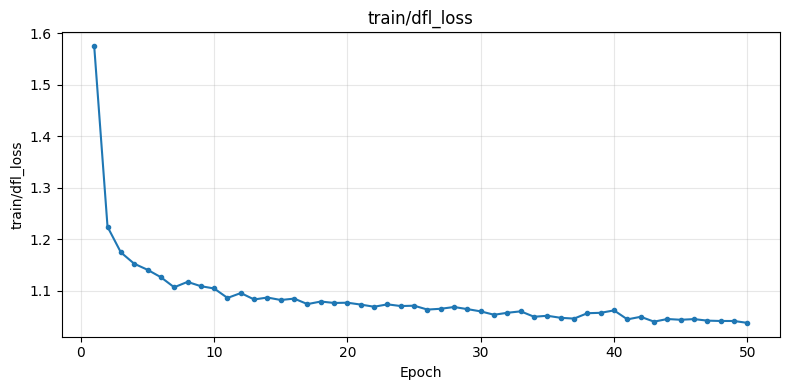

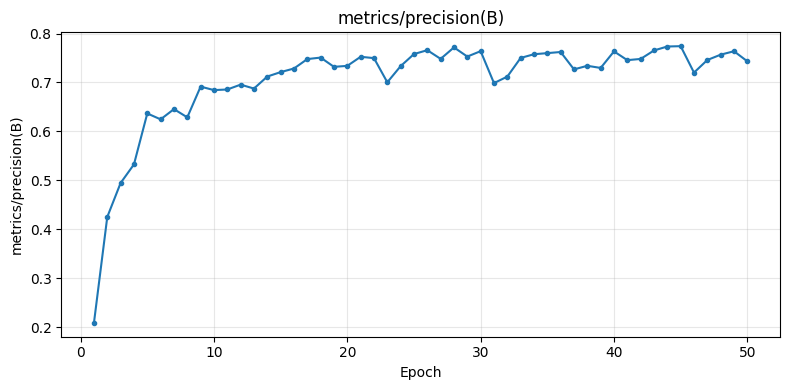

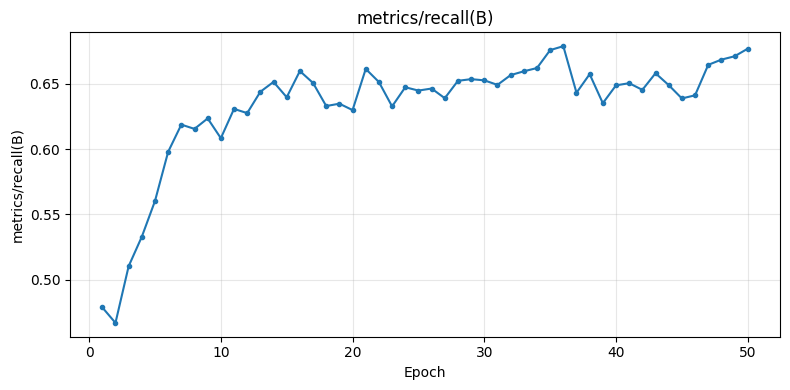

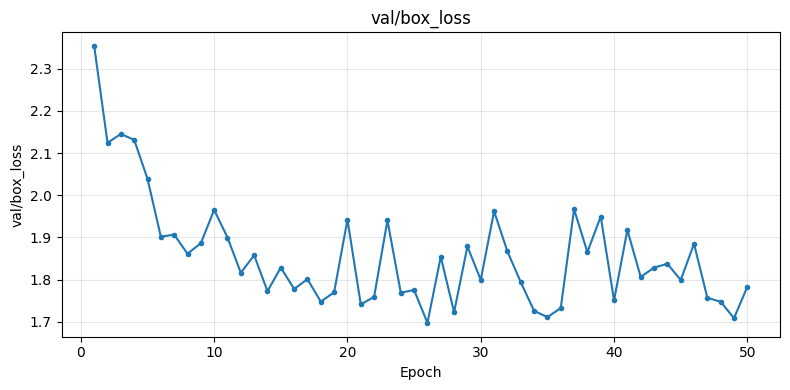

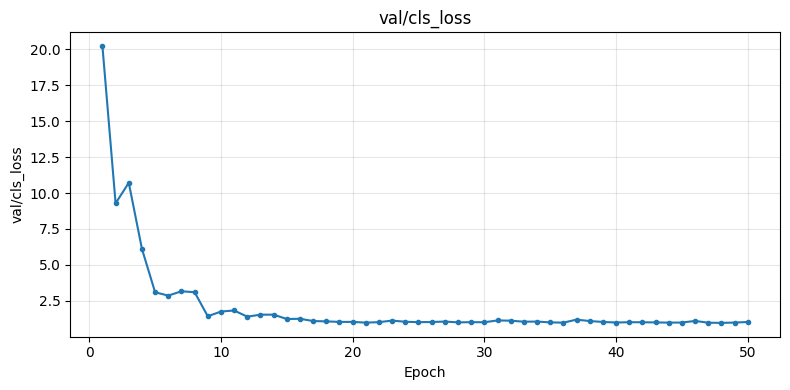

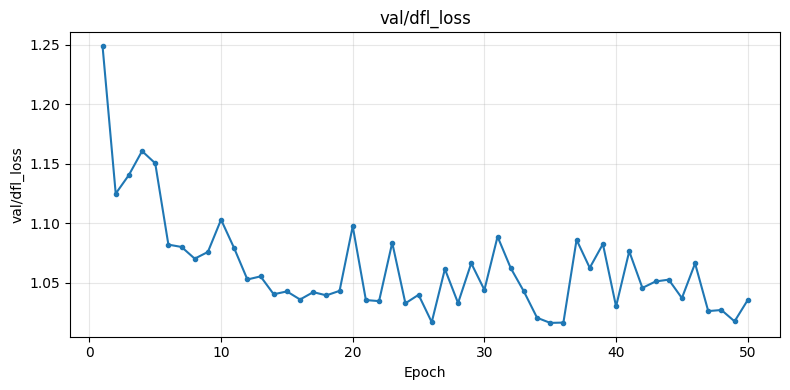

In [13]:
results_csv = BEST_WEIGHTS.parent.parent / "results.csv"
if not results_csv.exists():
    raise FileNotFoundError(f"Training history not found: {results_csv}")

history = pd.read_csv(results_csv)
history.columns = history.columns.str.strip()
print("Epochs recorded:", len(history))
display(history.tail())

metric_cols = [
    c for c in history.columns
    if any(term in c.lower() for term in
           ["train/box_loss", "train/cls_loss", "train/dfl_loss",
            "val/box_loss", "val/cls_loss", "val/dfl_loss",
            "metrics/precision", "metrics/recall", "metrics/mAP50",
            "metrics/mAP50-95"])
]
for col in metric_cols:
    plt.figure(figsize=(8, 4))
    plt.plot(np.arange(1, len(history) + 1), history[col], marker=".")
    plt.xlabel("Epoch")
    plt.ylabel(col)
    plt.title(col)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### 12.2 Official SomBench crater-specific test summary

,split,confidence,transform,TP,FP,FN,precision,recall,F1,median_detected_to_labelled_diameter_ratio,images
0,test,0.55,baseline,678,58,903,0.921196,0.428843,0.58524,0.969094,46


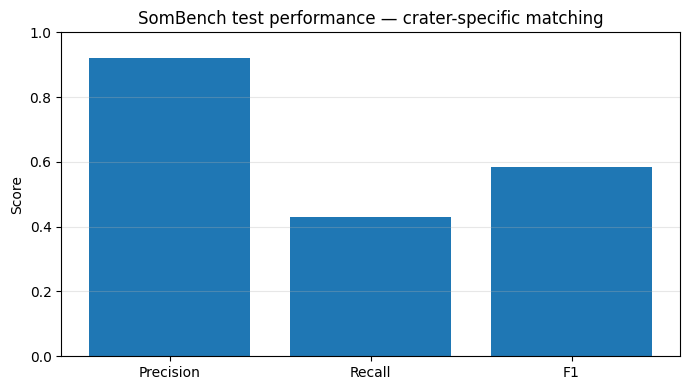

Frozen confidence threshold selected on validation: 0.55
Matching: Hungarian one-to-one; centre distance <= half GT diameter; diameter error <= 50%.


In [14]:
# Display the custom Hungarian-matching result already computed in Section 7.
# This does not rerun test inference or select a new threshold.
display(pd.DataFrame([test_summary]))

pooled_metrics = {
    "Precision": test_summary["precision"],
    "Recall": test_summary["recall"],
    "F1": test_summary["F1"],
}
plt.figure(figsize=(7, 4))
plt.bar(list(pooled_metrics.keys()), list(pooled_metrics.values()))
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("SomBench test performance — crater-specific matching")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Frozen confidence threshold selected on validation:", BEST_CONF)
print("Matching: Hungarian one-to-one; centre distance <= half GT diameter; diameter error <= 50%.")

### 12.3 Per-image performance and difficult tiles

,file_name,site,resolution_m,tp,fp,fn,precision,recall,f1,n_scored_gt,n_ignored_gt
43,images/NAC_DTM_REINER_PHO_E074N3010__standard_...,NAC_DTM_REINER_PHO_E074N3010,2.700000,3,0,33,1.000000,0.083333,0.153846,36,0
41,images/NAC_DTM_MARCH17_PHO_E207N3357__standard...,NAC_DTM_MARCH17_PHO_E207N3357,4.023437,40,1,329,0.975610,0.108401,0.195122,369,0
42,images/NAC_DTM_REINER_PHO_E074N3010__standard_...,NAC_DTM_REINER_PHO_E074N3010,2.700000,4,0,28,1.000000,0.125000,0.222222,32,0
45,images/NAC_DTM_REINER_PHO_E074N3010__standard_...,NAC_DTM_REINER_PHO_E074N3010,2.700000,6,1,37,0.857143,0.139535,0.240000,43,0
44,images/NAC_DTM_REINER_PHO_E074N3010__standard_...,NAC_DTM_REINER_PHO_E074N3010,2.700000,7,0,34,1.000000,0.170732,0.291667,41,0
22,images/NAC_DTM_KINGEJECTA_PHO_E041N1229__stand...,NAC_DTM_KINGEJECTA_PHO_E041N1229,0.900000,7,3,15,0.700000,0.318182,0.437500,22,169
33,images/NAC_DTM_KINGEJECTA_PHO_E041N1229__stand...,NAC_DTM_KINGEJECTA_PHO_E041N1229,0.900000,8,0,12,1.000000,0.400000,0.571429,20,152
6,images/NAC_DTM_HLNDPHOTOM2_PHO_E011N1499__stan...,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,1.100000,19,3,27,0.863636,0.413043,0.558824,46,95
9,images/NAC_DTM_HLNDPHOTOM2_PHO_E011N1499__stan...,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,1.100000,12,3,14,0.800000,0.461538,0.585366,26,70
24,images/NAC_DTM_KINGEJECTA_PHO_E041N1229__stand...,NAC_DTM_KINGEJECTA_PHO_E041N1229,0.900000,14,0,16,1.000000,0.466667,0.636364,30,180


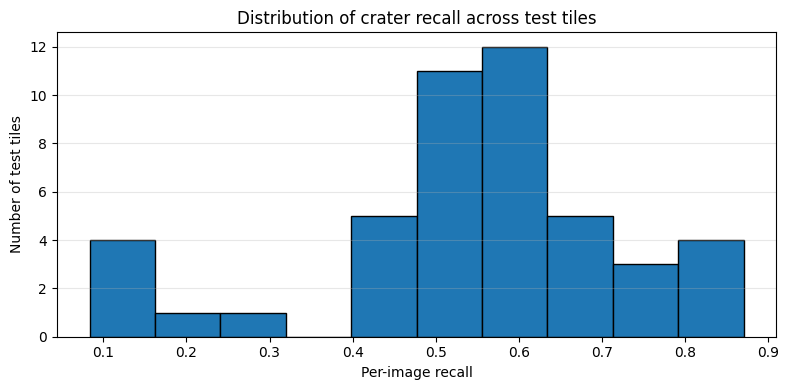

,site,images,TP,FP,FN,mean_recall,mean_F1
0,NAC_DTM_HLNDPHOTOM2_PHO_E011N1499,16,306,40,224,0.582717,0.696423
1,NAC_DTM_KINGEJECTA_PHO_E041N1229,25,312,16,218,0.600587,0.727904
2,NAC_DTM_MARCH17_PHO_E207N3357,1,40,1,329,0.108401,0.195122
3,NAC_DTM_REINER_PHO_E074N3010,4,20,1,132,0.129650,0.226934


In [15]:
cols = ["file_name", "site", "resolution_m", "tp", "fp", "fn",
        "precision", "recall", "f1", "n_scored_gt", "n_ignored_gt"]
display(test_df[cols].sort_values(["recall", "f1"]).head(15))

plt.figure(figsize=(8, 4))
plt.hist(test_df["recall"].dropna(), bins=10, edgecolor="black")
plt.xlabel("Per-image recall")
plt.ylabel("Number of test tiles")
plt.title("Distribution of crater recall across test tiles")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

site_analysis = test_df.groupby("site", dropna=False).agg(
    images=("image_id", "count"),
    TP=("tp", "sum"), FP=("fp", "sum"), FN=("fn", "sum"),
    mean_recall=("recall", "mean"), mean_F1=("f1", "mean")
).reset_index()
display(site_analysis)

### 12.4 Crater-size analysis

,size_bin,labelled_craters,detected,recall
0,20–50 m,544,136,0.250000
1,10–20 m,946,508,0.536998
2,50–100 m,49,20,0.408163
3,≥100 m,42,14,0.333333


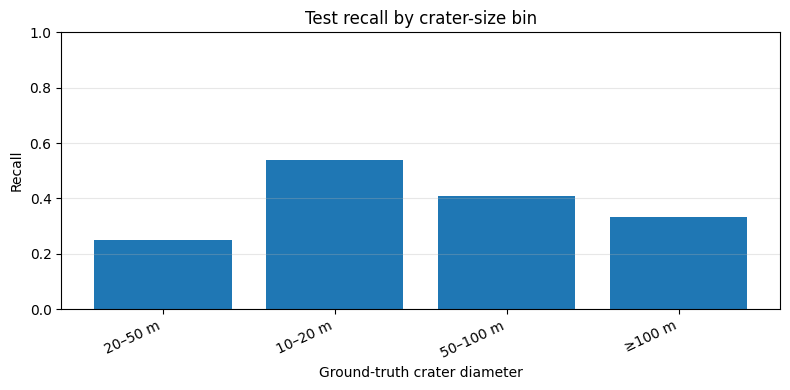

In [16]:
display(size_report)

if not size_report.empty:
    plt.figure(figsize=(8, 4))
    plt.bar(size_report["size_bin"], size_report["recall"])
    plt.ylim(0, 1)
    plt.xlabel("Ground-truth crater diameter")
    plt.ylabel("Recall")
    plt.title("Test recall by crater-size bin")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

### 12.5 Visual inspection of test predictions

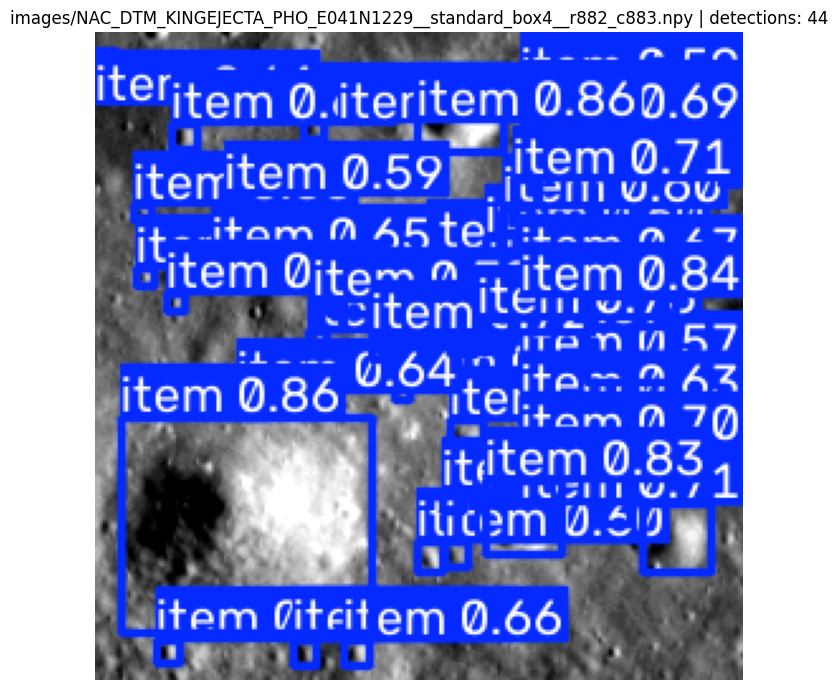

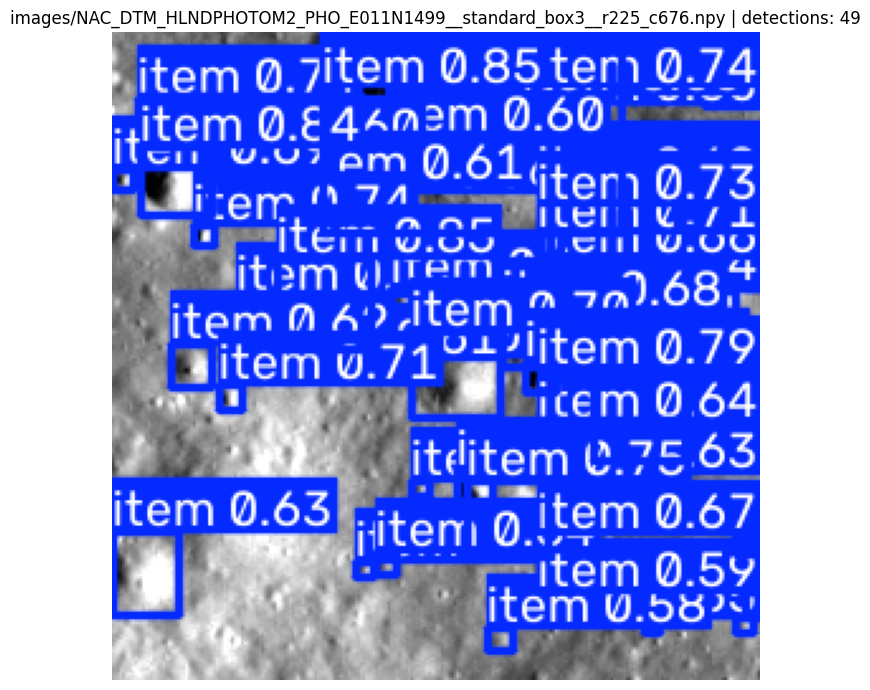

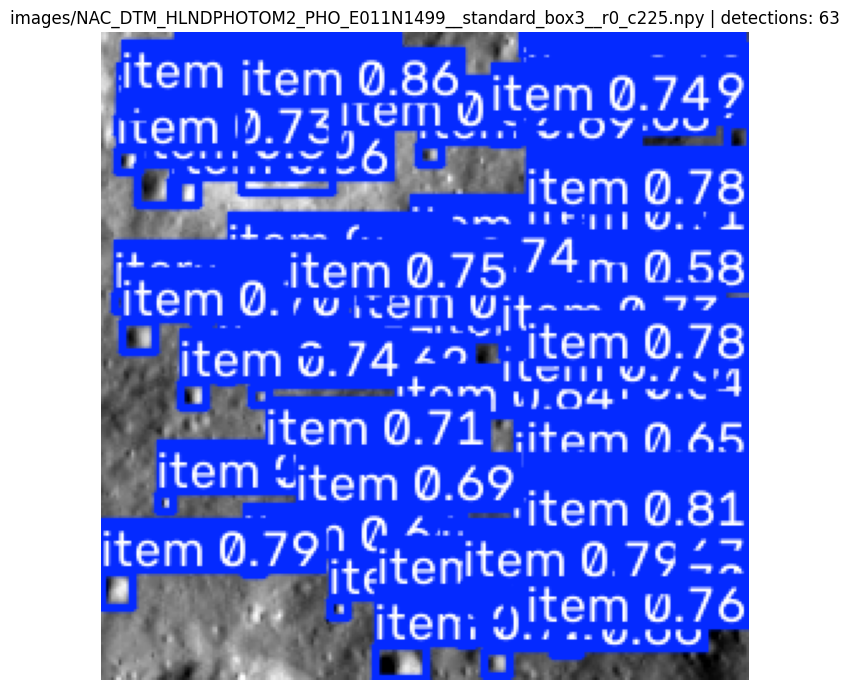

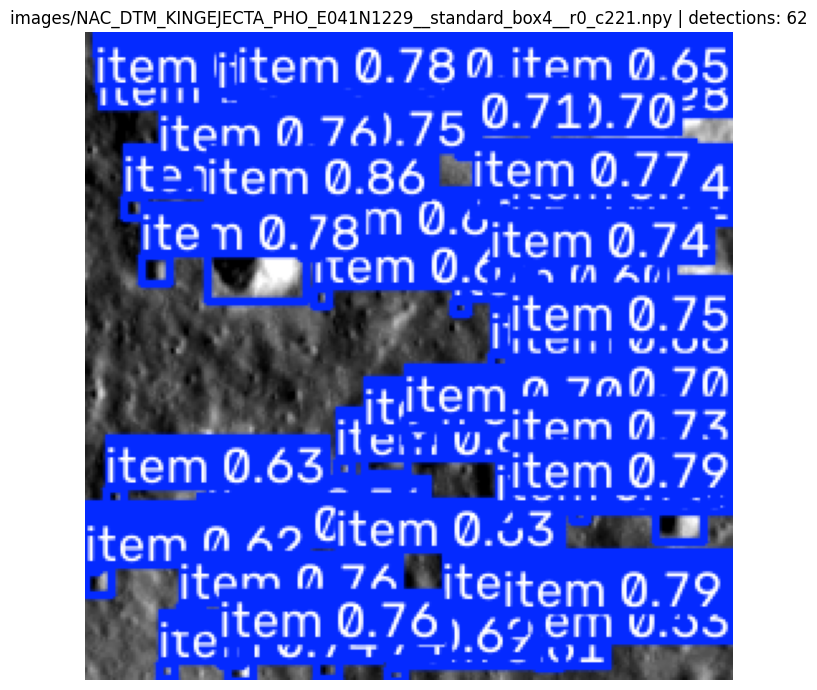

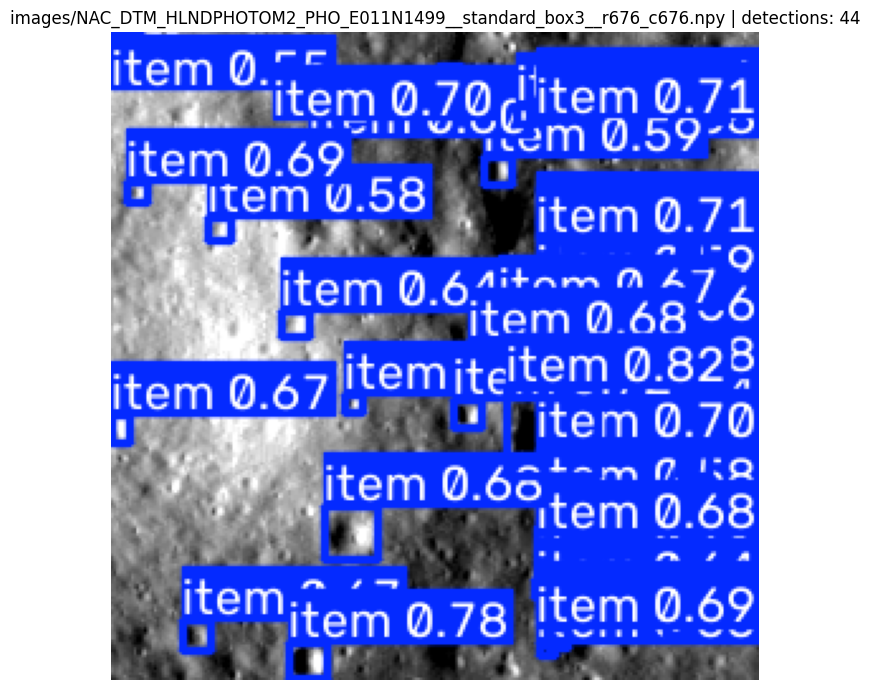

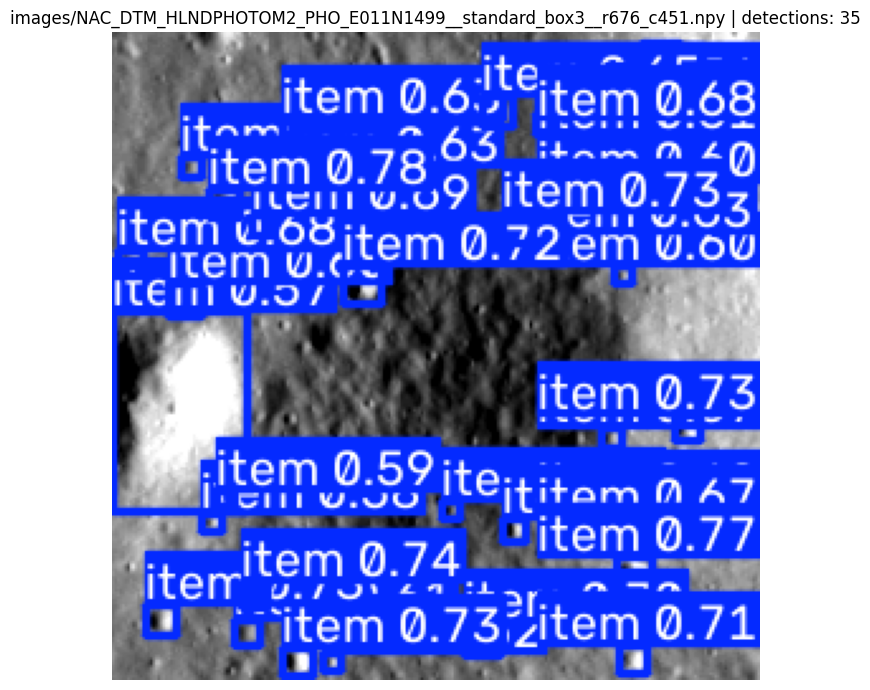

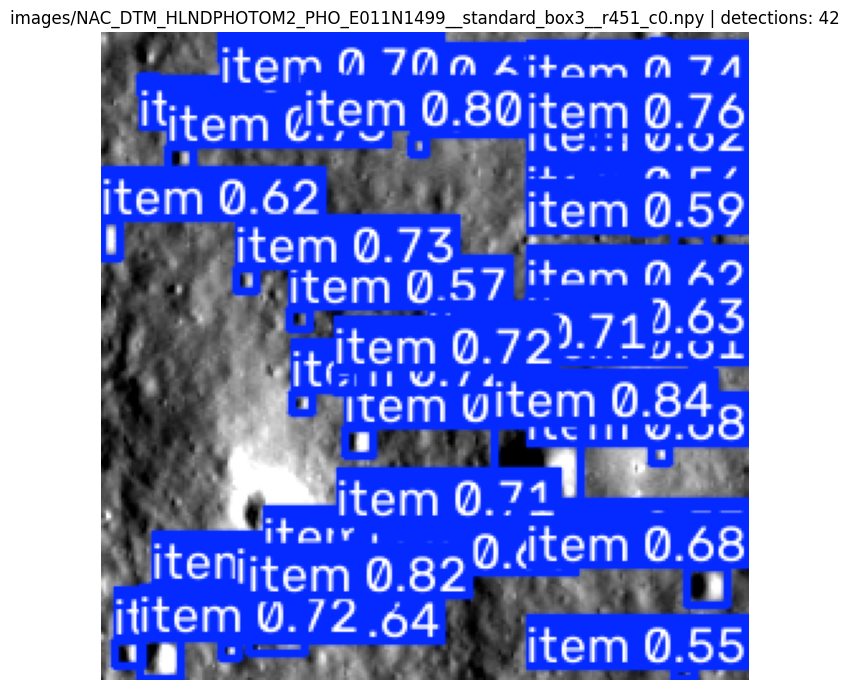

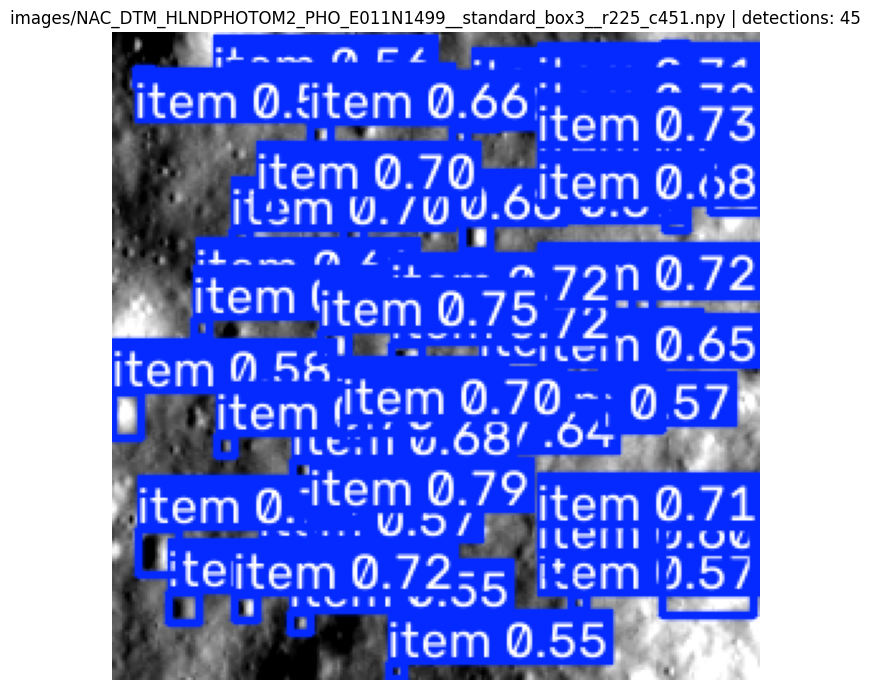

In [17]:
# Visual diagnostics only; do not use these test images to tune the model.
import random
rng = random.Random(SEED)
n_show = min(8, len(test_records))
chosen_records = rng.sample(test_records, n_show) if n_show else []

for rec in chosen_records:
    image_bgr = cv2.imread(rec["image_path"], cv2.IMREAD_COLOR)
    if image_bgr is None:
        print("Could not read:", rec["image_path"])
        continue
    pred = analysis_model.predict(
        source=image_bgr, imgsz=IMGSZ, conf=BEST_CONF,
        max_det=3000, verbose=False
    )[0]
    annotated = pred.plot()
    plt.figure(figsize=(7, 7))
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    n_det = len(pred.boxes) if pred.boxes is not None else 0
    plt.title(f'{rec["file_name"]} | detections: {n_det}')
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### 12.6 Save a compact model-analysis report

The files below are saved under `WORK`. Keep the checkpoint, training history, validation threshold sweep, and test metrics together for reproducibility.

In [18]:
analysis_report = {
    "checkpoint": str(BEST_WEIGHTS),
    "class_names": analysis_model.names,
    "validation_selected_confidence": float(BEST_CONF),
    "test_metrics": test_summary,
    "training_epochs_recorded": int(len(history)),
    "test_images": int(len(test_df)),
    "size_bin_recall": size_report.to_dict(orient="records"),
}
report_path = WORK / "model_analysis_report.json"
report_path.write_text(json.dumps(analysis_report, indent=2, default=str))

checkpoint_copy = WORK / "best_crater_model.pt"
if BEST_WEIGHTS.resolve() != checkpoint_copy.resolve():
    shutil.copy2(BEST_WEIGHTS, checkpoint_copy)

print("Analysis report:", report_path)
print("Checkpoint copy:", checkpoint_copy)
print("Training results:", results_csv)
print("Test metrics CSV:", WORK / "test_per_image_metrics.csv")
print("Test size-bin CSV:", WORK / "test_size_bin_recall.csv")

Analysis report: /kaggle/working/crater_yolo_work_fresh_v2/model_analysis_report.json
Checkpoint copy: /kaggle/working/crater_yolo_work_fresh_v2/best_crater_model.pt
Training results: /kaggle/working/crater_yolo_runs_fresh_v2/sombench_yolo11n_controlled_fresh_v2/results.csv
Test metrics CSV: /kaggle/working/crater_yolo_work_fresh_v2/test_per_image_metrics.csv
Test size-bin CSV: /kaggle/working/crater_yolo_work_fresh_v2/test_size_bin_recall.csv


## Final interpretation reminder

- The primary reported result is the custom SomBench crater-specific metric from Section 7, not YOLO's standard box mAP.
- YOLO training validation metrics and custom SomBench metrics are different protocols and must be labelled separately.
- Do not claim robustness to all illumination conditions: SomBench has limited illumination diversity.
- The test split is used only after training and validation-based threshold selection. Do not tune this experiment using its test result.
- Box-derived diameters are approximations; report the median predicted/labelled diameter ratio alongside detection metrics.
- Do not add a boulder filter or segmentation head without suitable annotations and a separate validation protocol.
- Attribute the SomBench NAC dataset to its authors and retain the dataset's CC BY 4.0 attribution requirements.


In [19]:
# Verify that all required variables are available

required = [
    "val_records",
    "val_prediction_cache",
    "val_model",
    "BEST_CONF",
    "WORK",
    "COCO"
]

missing = [v for v in required if v not in globals()]

if missing:
    raise RuntimeError(
        f"Missing variables: {missing}\n"
        "Run Cell 8 (data preparation) and Cell 14 "
        "(validation predictions and threshold selection) first."
    )

print("All prerequisites available.")
print("Validation images:", len(val_records))
print("Selected confidence:", BEST_CONF)

All prerequisites available.
Validation images: 52
Selected confidence: 0.55


Analysing validation errors:   0%|          | 0/52 [00:00<?, ?it/s]

Error analysis completed.
Total TP: 587
Total FN: 877
Total FP: 190


,file_name,site,resolution_m,status,gt_diameter_m,pred_diameter_m,confidence,centre_error_px,centre_error_normalised,diameter_relative_error,nearest_candidate_confidence,nearest_candidate_distance_px,nearest_candidate_diameter_error
0,images/NAC_DTM_A15SIVB_PHO_E009S3481__standard...,NAC_DTM_A15SIVB_PHO_E009S3481,4.023437,TP,488.626367,338.831641,0.699762,27.456610,0.226083,0.306563,NaN,NaN,NaN
1,images/NAC_DTM_A15SIVB_PHO_E009S3481__standard...,NAC_DTM_A15SIVB_PHO_E009S3481,4.023437,TP,37.780078,34.836338,0.577311,0.440536,0.046915,0.077918,NaN,NaN,NaN
2,images/NAC_DTM_A15SIVB_PHO_E009S3481__standard...,NAC_DTM_A15SIVB_PHO_E009S3481,4.023437,TP,24.824609,21.925156,0.564734,0.595656,0.096541,0.116798,NaN,NaN,NaN
3,images/NAC_DTM_A15SIVB_PHO_E009S3481__standard...,NAC_DTM_A15SIVB_PHO_E009S3481,4.023437,TP,26.433984,26.546860,0.666410,0.949950,0.144589,0.004270,NaN,NaN,NaN
4,images/NAC_DTM_A15SIVB_PHO_E009S3481__standard...,NAC_DTM_A15SIVB_PHO_E009S3481,4.023437,TP,35.969531,36.012485,0.636172,0.153697,0.017192,0.001194,NaN,NaN,NaN
5,images/NAC_DTM_A15SIVB_PHO_E009S3481__standard...,NAC_DTM_A15SIVB_PHO_E009S3481,4.023437,TP,23.456641,25.135246,0.608181,0.359363,0.061640,0.071562,NaN,NaN,NaN
6,images/NAC_DTM_A15SIVB_PHO_E009S3481__standard...,NAC_DTM_A15SIVB_PHO_E009S3481,4.023437,TP,42.326562,38.424930,0.668880,1.464517,0.139213,0.092179,NaN,NaN,NaN
7,images/NAC_DTM_A15SIVB_PHO_E009S3481__standard...,NAC_DTM_A15SIVB_PHO_E009S3481,4.023437,TP,68.338086,67.530974,0.678602,1.089361,0.064137,0.011811,NaN,NaN,NaN
8,images/NAC_DTM_A15SIVB_PHO_E009S3481__standard...,NAC_DTM_A15SIVB_PHO_E009S3481,4.023437,TP,42.286328,37.236412,0.618326,0.878438,0.083581,0.119422,NaN,NaN,NaN
9,images/NAC_DTM_A15SIVB_PHO_E009S3481__standard...,NAC_DTM_A15SIVB_PHO_E009S3481,4.023437,TP,35.708008,35.248471,0.583557,1.109760,0.125043,0.012869,NaN,NaN,NaN



Matched prediction confidence:
count    587.000000
mean       0.723973
std        0.079591
min        0.551019
25%        0.660631
50%        0.732068
75%        0.787808
max        0.905022
dtype: float64

False-positive confidence:
count    190.000000
mean       0.611894
std        0.050918
min        0.550383
25%        0.576887
50%        0.602131
75%        0.631240
max        0.801299
dtype: float64

Nearest low-threshold candidate confidence for missed craters:
count    877.000000
mean       0.122624
std        0.150210
min        0.001004
25%        0.032054
50%        0.056746
75%        0.137707
max        0.713960
dtype: float64


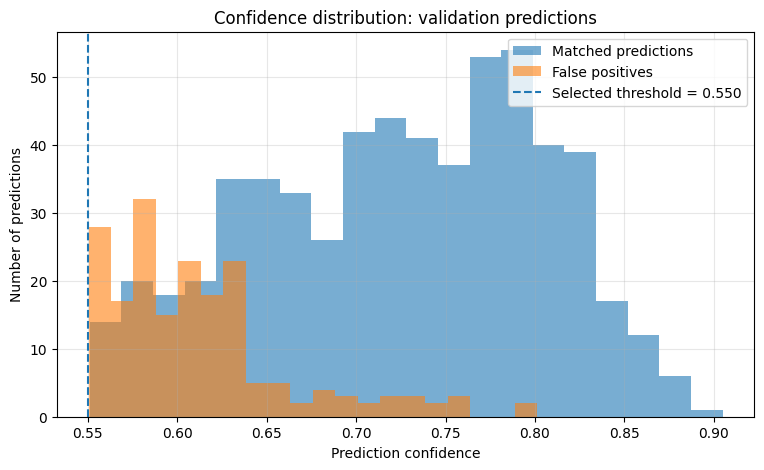

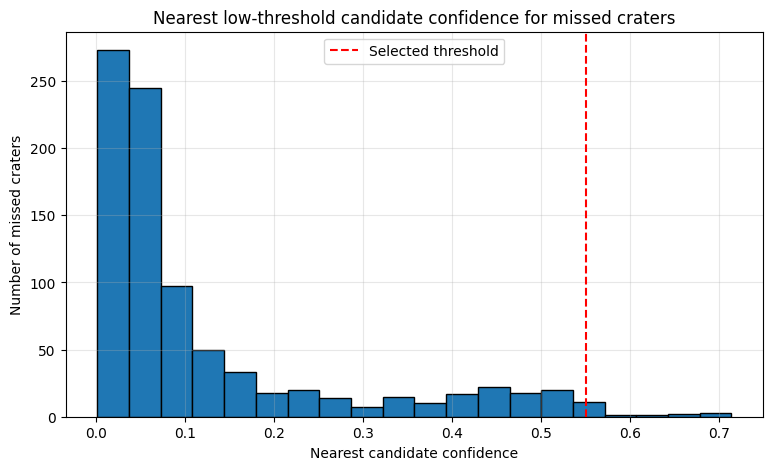


SITE-WISE VALIDATION PERFORMANCE


,site,images,TP,FP,FN,GT,precision,recall
0,NAC_DTM_A15SIVB_PHO_E009S3481,1,39,2,148,187,0.951220,0.208556
1,NAC_DTM_Apollo17_PHO_E199N0308,25,274,71,172,446,0.794203,0.614350
2,NAC_DTM_KINGEJECTA_PHO_E041N1229,25,254,116,78,332,0.686486,0.765060
3,NAC_DTM_MARCH17_PHO_E207N3357,1,20,1,479,499,0.952381,0.040080



RESOLUTION-WISE VALIDATION PERFORMANCE


,resolution_group,images,TP,FP,FN,GT,precision,recall
0,<=1.5 m/px,50,528,187,250,778,0.738462,0.678663
1,>3.0 m/px,2,59,3,627,686,0.951613,0.086006



VALIDATION IMAGES WITH MOST MISSED CRATERS


,image_id,file_name,site,resolution_m,FN,FP,TP
51,371,images/NAC_DTM_MARCH17_PHO_E207N3357__standard...,NAC_DTM_MARCH17_PHO_E207N3357,4.023437,479,1,20
0,3,images/NAC_DTM_A15SIVB_PHO_E009S3481__standard...,NAC_DTM_A15SIVB_PHO_E009S3481,4.023437,148,2,39
21,92,images/NAC_DTM_Apollo17_PHO_E199N0308__standar...,NAC_DTM_Apollo17_PHO_E199N0308,0.900000,15,0,17
8,79,images/NAC_DTM_Apollo17_PHO_E199N0308__standar...,NAC_DTM_Apollo17_PHO_E199N0308,0.900000,12,3,9
4,75,images/NAC_DTM_Apollo17_PHO_E199N0308__standar...,NAC_DTM_Apollo17_PHO_E199N0308,0.900000,11,1,10
11,82,images/NAC_DTM_Apollo17_PHO_E199N0308__standar...,NAC_DTM_Apollo17_PHO_E199N0308,0.900000,11,2,12
16,87,images/NAC_DTM_Apollo17_PHO_E199N0308__standar...,NAC_DTM_Apollo17_PHO_E199N0308,0.900000,10,3,18
7,78,images/NAC_DTM_Apollo17_PHO_E199N0308__standar...,NAC_DTM_Apollo17_PHO_E199N0308,0.900000,9,2,8
2,73,images/NAC_DTM_Apollo17_PHO_E199N0308__standar...,NAC_DTM_Apollo17_PHO_E199N0308,0.900000,9,6,11
22,93,images/NAC_DTM_Apollo17_PHO_E199N0308__standar...,NAC_DTM_Apollo17_PHO_E199N0308,0.900000,8,1,17


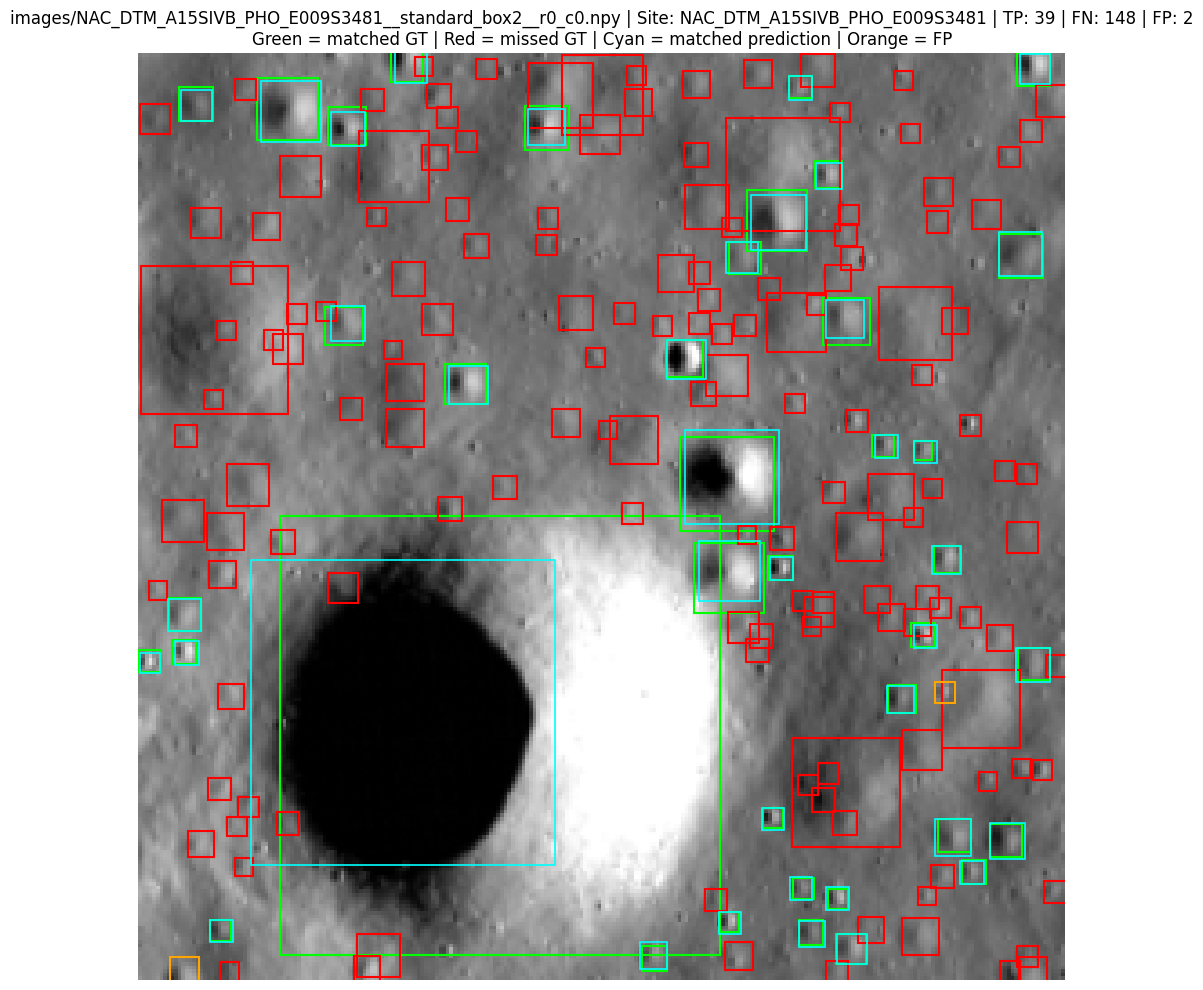

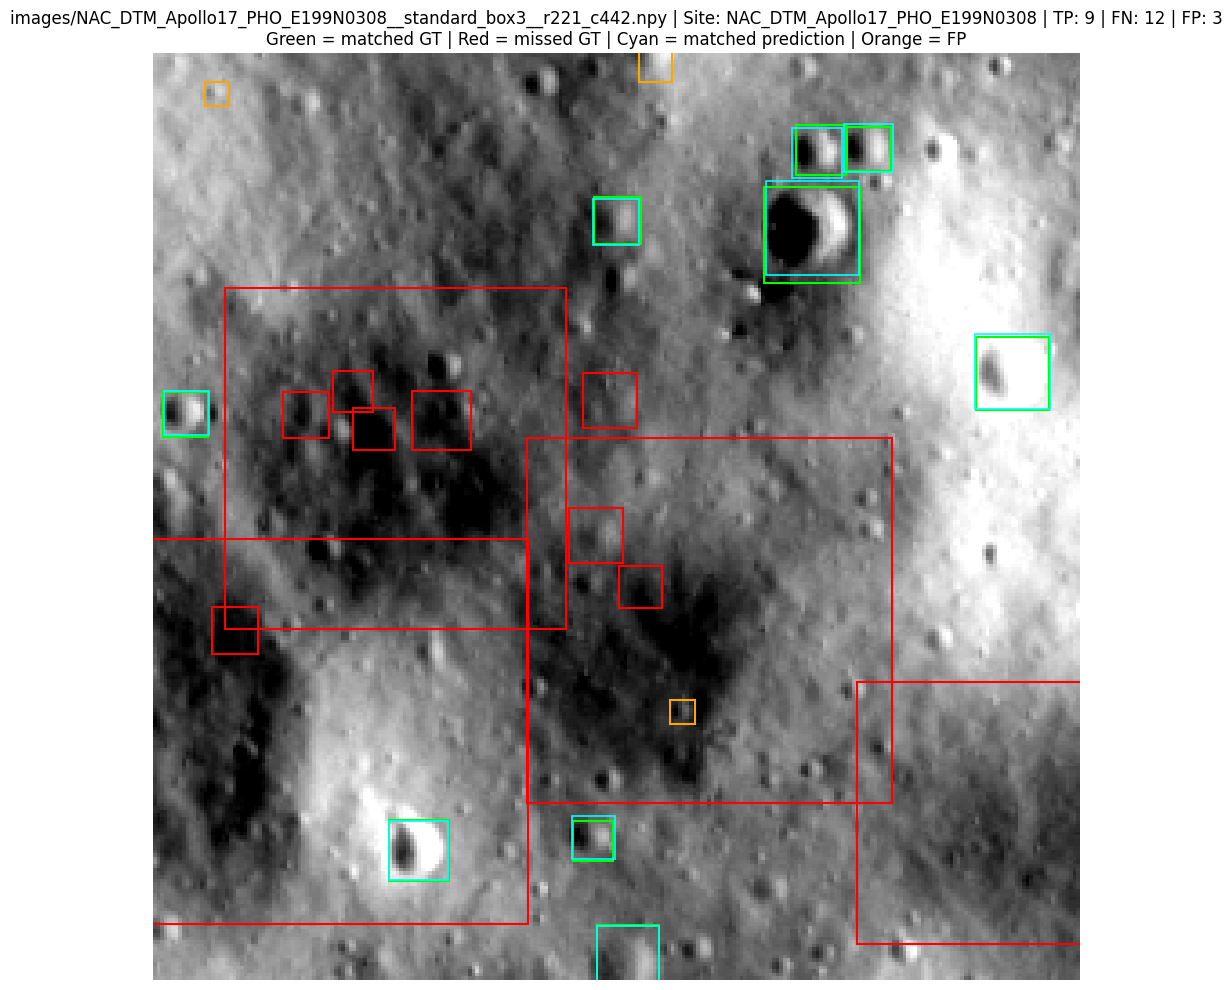

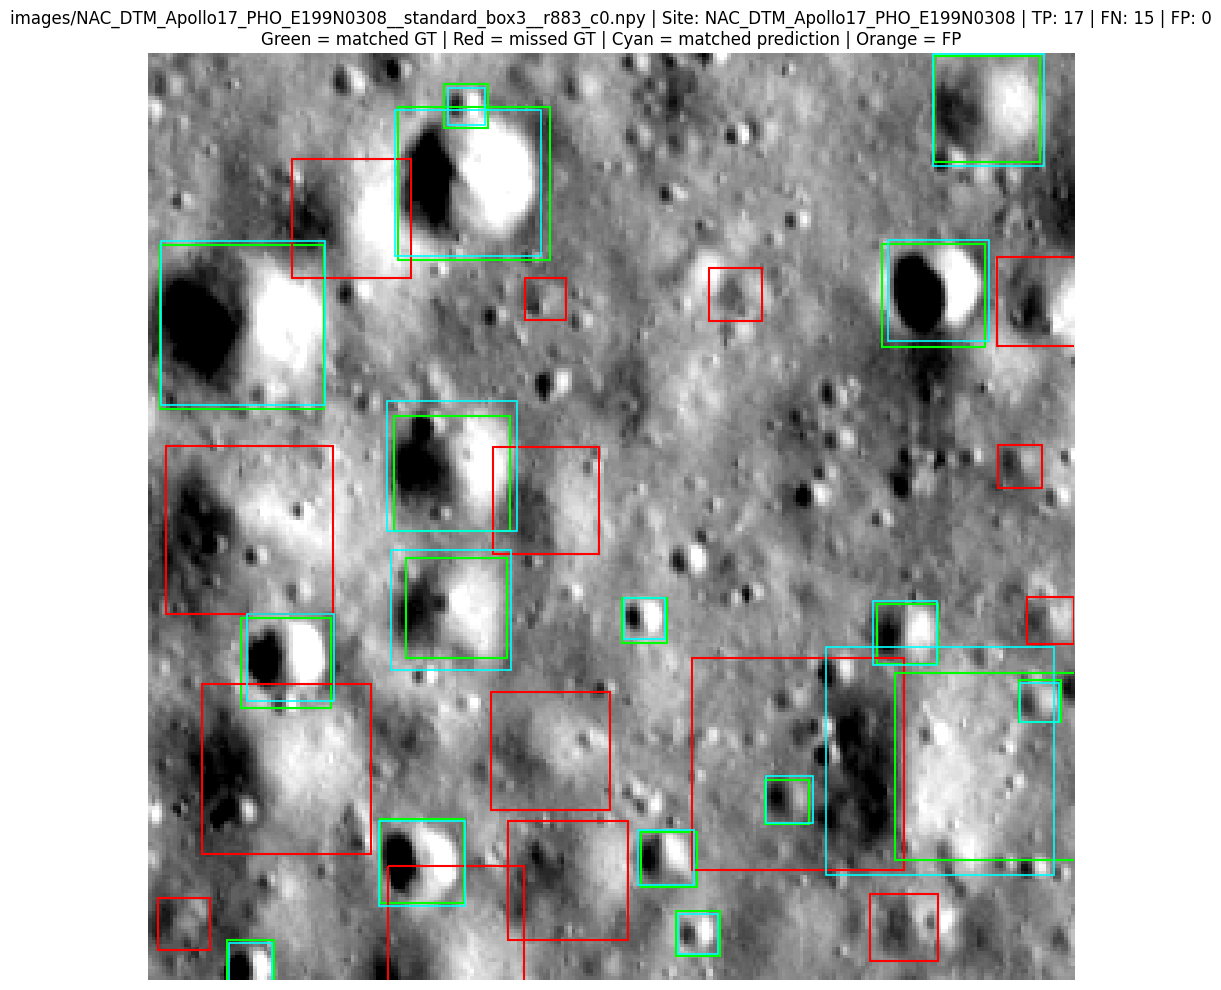

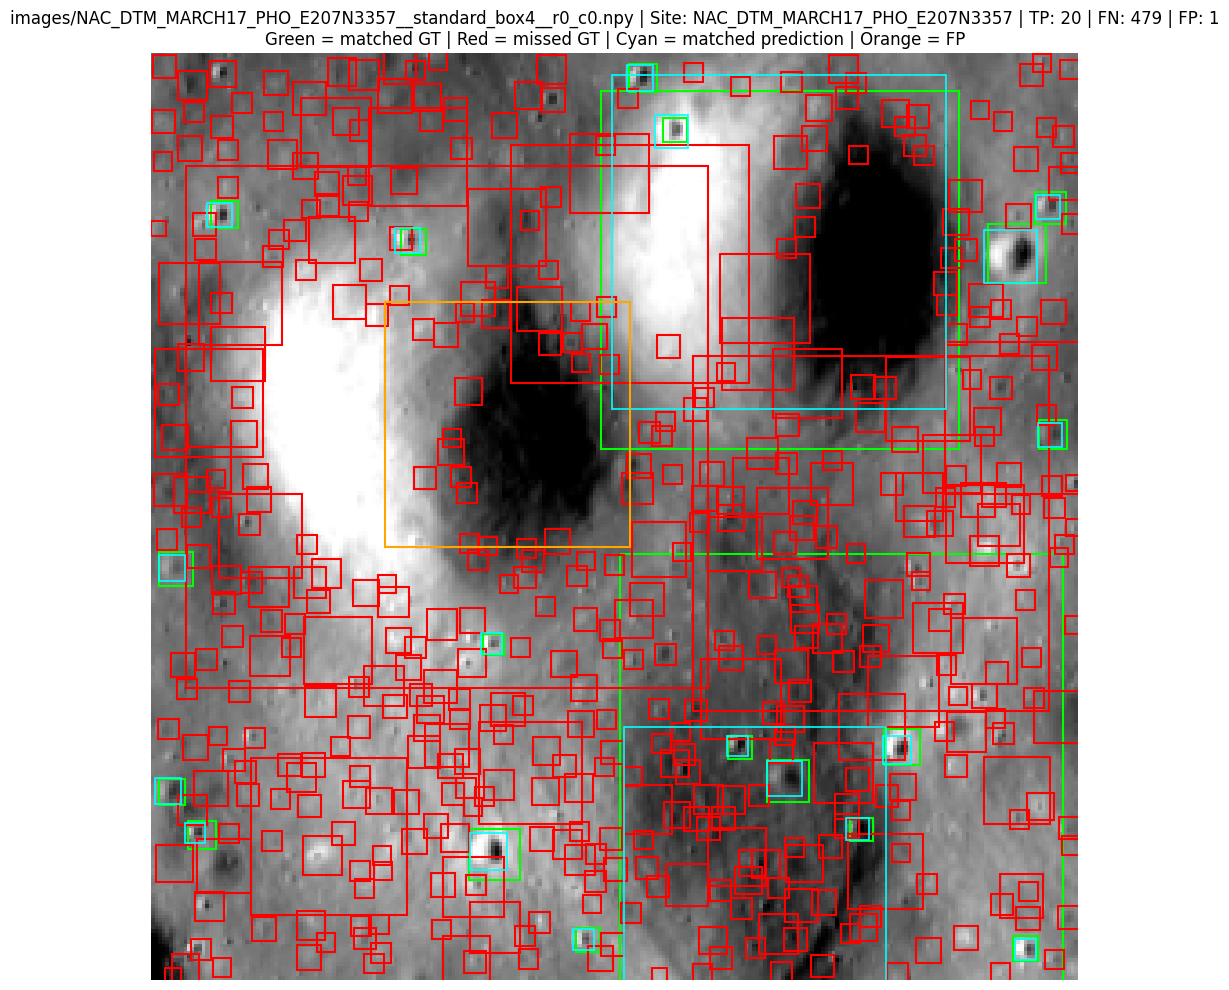


All diagnostic files saved to: /kaggle/working/crater_yolo_work_fresh_v2
 - validation_detailed_errors.csv
 - validation_resolution_analysis.csv
 - validation_site_error_analysis.csv
 - validation_image_error_analysis.csv

Detailed error analysis complete.


In [20]:

# ============================================================
# SECTION 12.7 — DETAILED ERROR ANALYSIS (VALIDATION SET)
# Reuses the trained model and cached validation predictions.
# Does NOT retrain the model.
# ============================================================

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Match predictions and ground truth, retaining error details
# ------------------------------------------------------------

def detailed_match(rec):
    image_id = rec["image_id"]
    _, gt_all = coco_gt_for_image("val", image_id)

    scored_gt = [g for g in gt_all if g["diam_m"] >= MIN_DIAMETER_M]
    ignored_gt = [g for g in gt_all if g["diam_m"] < MIN_DIAMETER_M]

    # Cached predictions were generated at confidence 0.001.
    all_preds = val_prediction_cache[image_id]
    preds = [p for p in all_preds if p["conf"] >= BEST_CONF]

    valid = np.zeros((len(scored_gt), len(preds)), dtype=bool)
    cost = np.full((len(scored_gt), len(preds)), 1e6)

    for i, g in enumerate(scored_gt):
        for j, p in enumerate(preds):
            distance = math.hypot(
                p["cx"] - g["cx"],
                p["cy"] - g["cy"]
            )
            diameter_error = abs(
                p["diam_px"] - g["diam_px"]
            ) / max(g["diam_px"], 1e-9)

            if distance <= 0.5 * g["diam_px"] and diameter_error <= 0.5:
                valid[i, j] = True
                cost[i, j] = (
                    distance / max(0.5 * g["diam_px"], 1e-9)
                    + diameter_error
                )

    if len(scored_gt) and len(preds):
        rows, cols = linear_sum_assignment(cost)
        matches = [
            (i, j) for i, j in zip(rows, cols)
            if valid[i, j]
        ]
    else:
        matches = []

    matched_gt = {i for i, j in matches}
    matched_preds = {j for i, j in matches}

    # Identify predictions matching ignored (<10m) craters.
    ignored_preds = set()

    for j, p in enumerate(preds):
        if j in matched_preds:
            continue

        for g in ignored_gt:
            distance = math.hypot(
                p["cx"] - g["cx"],
                p["cy"] - g["cy"]
            )
            diameter_error = abs(
                p["diam_px"] - g["diam_px"]
            ) / max(g["diam_px"], 1e-9)

            if distance <= 0.5 * g["diam_px"] and diameter_error <= 0.5:
                ignored_preds.add(j)
                break

    false_negative_indices = [
        i for i in range(len(scored_gt)) if i not in matched_gt
    ]

    false_positive_indices = [
        j for j in range(len(preds))
        if j not in matched_preds and j not in ignored_preds
    ]

    return {
        "gt": scored_gt,
        "ignored_gt": ignored_gt,
        "preds": preds,
        "all_preds": all_preds,
        "matches": matches,
        "fn_indices": false_negative_indices,
        "fp_indices": false_positive_indices,
        "ignored_pred_indices": ignored_preds
    }


# ------------------------------------------------------------
# 2. Build a detailed per-crater error table
# ------------------------------------------------------------

error_rows = []
matched_confidences = []
fp_confidences = []
missed_nearest_confidences = []

for rec in tqdm(val_records, desc="Analysing validation errors"):

    result = detailed_match(rec)

    gt = result["gt"]
    preds = result["preds"]
    all_preds = result["all_preds"]

    matched_gt = {i for i, j in result["matches"]}

    # Matched craters
    for i, j in result["matches"]:
        g, p = gt[i], preds[j]

        distance = math.hypot(
            p["cx"] - g["cx"],
            p["cy"] - g["cy"]
        )

        matched_confidences.append(p["conf"])

        error_rows.append({
            "file_name": rec["file_name"],
            "site": rec["site"],
            "resolution_m": rec["resolution_m"],
            "status": "TP",
            "gt_diameter_m": g["diam_m"],
            "pred_diameter_m": p["diam_px"] * rec["resolution_m"],
            "confidence": p["conf"],
            "centre_error_px": distance,
            "centre_error_normalised": distance / max(g["diam_px"], 1e-9),
            "diameter_relative_error": abs(
                p["diam_px"] - g["diam_px"]
            ) / max(g["diam_px"], 1e-9)
        })

    # Missed craters: find nearest prediction from the low-confidence cache.
    for i in result["fn_indices"]:
        g = gt[i]

        if all_preds:
            nearest = min(
                all_preds,
                key=lambda p: math.hypot(
                    p["cx"] - g["cx"],
                    p["cy"] - g["cy"]
                )
            )

            distance = math.hypot(
                nearest["cx"] - g["cx"],
                nearest["cy"] - g["cy"]
            )

            nearest_conf = nearest["conf"]
            nearest_diameter_error = abs(
                nearest["diam_px"] - g["diam_px"]
            ) / max(g["diam_px"], 1e-9)

            missed_nearest_confidences.append(nearest_conf)
        else:
            distance = np.nan
            nearest_conf = np.nan
            nearest_diameter_error = np.nan

        error_rows.append({
            "file_name": rec["file_name"],
            "site": rec["site"],
            "resolution_m": rec["resolution_m"],
            "status": "FN",
            "gt_diameter_m": g["diam_m"],
            "pred_diameter_m": np.nan,
            "confidence": np.nan,
            "centre_error_px": np.nan,
            "centre_error_normalised": np.nan,
            "diameter_relative_error": np.nan,
            "nearest_candidate_confidence": nearest_conf,
            "nearest_candidate_distance_px": distance,
            "nearest_candidate_diameter_error": nearest_diameter_error
        })

    # False-positive predictions
    for j in result["fp_indices"]:
        p = preds[j]
        fp_confidences.append(p["conf"])

        error_rows.append({
            "file_name": rec["file_name"],
            "site": rec["site"],
            "resolution_m": rec["resolution_m"],
            "status": "FP",
            "gt_diameter_m": np.nan,
            "pred_diameter_m": p["diam_px"] * rec["resolution_m"],
            "confidence": p["conf"],
            "centre_error_px": np.nan,
            "centre_error_normalised": np.nan,
            "diameter_relative_error": np.nan
        })

error_df = pd.DataFrame(error_rows)

print("Error analysis completed.")
print("Total TP:", (error_df["status"] == "TP").sum())
print("Total FN:", (error_df["status"] == "FN").sum())
print("Total FP:", (error_df["status"] == "FP").sum())

display(error_df.head(20))

error_df.to_csv(WORK / "validation_detailed_errors.csv", index=False)


# ------------------------------------------------------------
# 3. Confidence analysis
# ------------------------------------------------------------

print("\nMatched prediction confidence:")
print(pd.Series(matched_confidences).describe())

print("\nFalse-positive confidence:")
print(pd.Series(fp_confidences).describe())

print("\nNearest low-threshold candidate confidence for missed craters:")
print(pd.Series(missed_nearest_confidences).describe())

plt.figure(figsize=(9, 5))

if matched_confidences:
    plt.hist(
        matched_confidences, bins=20, alpha=0.6,
        label="Matched predictions"
    )

if fp_confidences:
    plt.hist(
        fp_confidences, bins=20, alpha=0.6,
        label="False positives"
    )

plt.axvline(
    BEST_CONF, linestyle="--",
    label=f"Selected threshold = {BEST_CONF:.3f}"
)

plt.xlabel("Prediction confidence")
plt.ylabel("Number of predictions")
plt.title("Confidence distribution: validation predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(9, 5))

if missed_nearest_confidences:
    plt.hist(
        missed_nearest_confidences,
        bins=20, edgecolor="black"
    )

plt.axvline(
    BEST_CONF, color="red", linestyle="--",
    label="Selected threshold"
)

plt.xlabel("Nearest candidate confidence")
plt.ylabel("Number of missed craters")
plt.title("Nearest low-threshold candidate confidence for missed craters")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ------------------------------------------------------------
# 4. Site-wise and resolution-wise validation performance
# ------------------------------------------------------------

site_rows = []

for rec in val_records:
    r = detailed_match(rec)

    tp = len(r["matches"])
    fn = len(r["fn_indices"])
    fp = len(r["fp_indices"])

    site_rows.append({
        "site": rec["site"],
        "resolution_m": rec["resolution_m"],
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "GT": len(r["gt"]),
        "precision": tp / (tp + fp) if tp + fp else 0,
        "recall": tp / (tp + fn) if tp + fn else 0
    })

site_df = pd.DataFrame(site_rows)

print("\nSITE-WISE VALIDATION PERFORMANCE")
site_report_detailed = site_df.groupby("site").agg(
    images=("site", "count"),
    TP=("TP", "sum"),
    FP=("FP", "sum"),
    FN=("FN", "sum"),
    GT=("GT", "sum")
).reset_index()

site_report_detailed["precision"] = (
    site_report_detailed["TP"] /
    (site_report_detailed["TP"] + site_report_detailed["FP"])
)

site_report_detailed["recall"] = (
    site_report_detailed["TP"] /
    site_report_detailed["GT"]
)

display(site_report_detailed)


# Resolution categories are descriptive, not a model transformation.
def resolution_group(r):
    if r <= 1.5:
        return "<=1.5 m/px"
    elif r <= 3.0:
        return "1.5–3.0 m/px"
    return ">3.0 m/px"

site_df["resolution_group"] = site_df["resolution_m"].apply(
    resolution_group
)

resolution_report = site_df.groupby("resolution_group").agg(
    images=("resolution_m", "count"),
    TP=("TP", "sum"),
    FP=("FP", "sum"),
    FN=("FN", "sum"),
    GT=("GT", "sum")
).reset_index()

resolution_report["precision"] = (
    resolution_report["TP"] /
    (resolution_report["TP"] + resolution_report["FP"])
)

resolution_report["recall"] = (
    resolution_report["TP"] /
    resolution_report["GT"]
)

print("\nRESOLUTION-WISE VALIDATION PERFORMANCE")
display(resolution_report)

resolution_report.to_csv(
    WORK / "validation_resolution_analysis.csv",
    index=False
)


# ------------------------------------------------------------
# 5. Visualise actual TP, FN and FP on validation images
# ------------------------------------------------------------

def show_error_overlay(rec):
    result = detailed_match(rec)

    image = cv2.imread(
        rec["image_path"], cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        print("Could not load:", rec["image_path"])
        return

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(image, cmap="gray")

    gt = result["gt"]
    preds = result["preds"]

    # Ground truth and missed craters
    matched_gt = {i for i, j in result["matches"]}

    for i, g in enumerate(gt):
        x = g["cx"] - g["diam_px"] / 2
        y = g["cy"] - g["diam_px"] / 2
        color = "lime" if i in matched_gt else "red"

        ax.add_patch(plt.Rectangle(
            (x, y), g["diam_px"], g["diam_px"],
            fill=False, edgecolor=color, linewidth=1.5
        ))

    # Matched predictions (cyan)
    for i, j in result["matches"]:
        p = preds[j]
        d = p["diam_px"]

        ax.add_patch(plt.Rectangle(
            (p["cx"] - d/2, p["cy"] - d/2),
            d, d, fill=False,
            edgecolor="cyan", linewidth=1.2
        ))

    # False positives (orange)
    for j in result["fp_indices"]:
        p = preds[j]
        d = p["diam_px"]

        ax.add_patch(plt.Rectangle(
            (p["cx"] - d/2, p["cy"] - d/2),
            d, d, fill=False,
            edgecolor="orange", linewidth=1.5
        ))

    ax.set_title(
        f'{rec["file_name"]} | Site: {rec["site"]} | '
        f'TP: {len(result["matches"])} | '
        f'FN: {len(result["fn_indices"])} | '
        f'FP: {len(result["fp_indices"])}\n'
        'Green = matched GT | Red = missed GT | '
        'Cyan = matched prediction | Orange = FP'
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()


# Select validation images with the highest number of missed craters.
image_error_rows = []

for rec in val_records:
    r = detailed_match(rec)
    image_error_rows.append({
        "image_id": rec["image_id"],
        "file_name": rec["file_name"],
        "site": rec["site"],
        "resolution_m": rec["resolution_m"],
        "FN": len(r["fn_indices"]),
        "FP": len(r["fp_indices"]),
        "TP": len(r["matches"])
    })

image_error_df = pd.DataFrame(image_error_rows)

print("\nVALIDATION IMAGES WITH MOST MISSED CRATERS")
display(
    image_error_df.sort_values("FN", ascending=False).head(10)
)

worst_ids = set(
    image_error_df.nlargest(4, "FN")["image_id"]
)

for rec in val_records:
    if rec["image_id"] in worst_ids:
        show_error_overlay(rec)


# ------------------------------------------------------------
# 6. Save all diagnostic tables
# ------------------------------------------------------------

site_report_detailed.to_csv(
    WORK / "validation_site_error_analysis.csv",
    index=False
)

image_error_df.to_csv(
    WORK / "validation_image_error_analysis.csv",
    index=False
)

print("\nAll diagnostic files saved to:", WORK)
print(" - validation_detailed_errors.csv")
print(" - validation_resolution_analysis.csv")
print(" - validation_site_error_analysis.csv")
print(" - validation_image_error_analysis.csv")
print("\nDetailed error analysis complete.")


In [21]:
# ============================================================
# FINE-TUNING EXPERIMENT — BASELINE SNAPSHOT
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import shutil

# Preserve original checkpoint
BASELINE_WEIGHTS = Path(BEST_WEIGHTS).resolve()

assert BASELINE_WEIGHTS.exists(), "Original checkpoint missing!"

# Preserve original threshold
BASELINE_CONF = float(BEST_CONF)

# Evaluate original model using existing cached predictions
baseline_val_df, baseline_val_summary = evaluate_records(
    val_model,
    "val",
    val_records,
    BASELINE_CONF,
    transform="baseline",
    prediction_cache=val_prediction_cache
)

print("BASELINE MODEL")
print(json.dumps(baseline_val_summary, indent=2))

# Save baseline results
baseline_val_df.to_csv(
    WORK / "baseline_validation_metrics.csv",
    index=False
)

print("\nBaseline checkpoint:", BASELINE_WEIGHTS)
print("Baseline confidence:", BASELINE_CONF)

Evaluate val conf=0.55:   0%|          | 0/52 [00:00<?, ?it/s]

BASELINE MODEL
{
  "split": "val",
  "confidence": 0.55,
  "transform": "baseline",
  "TP": 587,
  "FP": 190,
  "FN": 877,
  "precision": 0.7554697554697555,
  "recall": 0.40095628415300544,
  "F1": 0.5238732708612227,
  "median_detected_to_labelled_diameter_ratio": 1.0018447014958767,
  "images": 52
}

Baseline checkpoint: /kaggle/working/crater_yolo_runs_fresh_v2/sombench_yolo11n_controlled_fresh_v2/weights/best.pt
Baseline confidence: 0.55


In [22]:
# ============================================================
# CONTROLLED FINE-TUNING — YOLO11n
# ============================================================

import torch
from ultralytics import YOLO

# Load the existing crater-specific checkpoint
finetune_model = YOLO(str(BASELINE_WEIGHTS))

FINETUNE_EPOCHS = 30
FINETUNE_PATIENCE = 8
FINETUNE_LR = 0.0001

print("Starting from:", BASELINE_WEIGHTS)

finetune_results = finetune_model.train(

    # Dataset
    data=str(data_yaml),

    # Training
    imgsz=640,
    epochs=FINETUNE_EPOCHS,
    patience=FINETUNE_PATIENCE,
    batch=BATCH,
    single_cls=True,

    # Conservative optimisation
    optimizer="AdamW",
    lr0=FINETUNE_LR,
    lrf=0.01,
    weight_decay=0.0005,
    cos_lr=True,
    warmup_epochs=1,

    # Geometry augmentation
    fliplr=0.5,
    flipud=0.5,
    degrees=0.0,
    scale=0.10,
    translate=0.03,
    shear=0.0,
    perspective=0.0,

    # Grayscale imagery
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.10,

    # Moderate mosaic
    mosaic=0.15,
    close_mosaic=5,
    mixup=0.0,
    copy_paste=0.0,

    # Reproducibility
    seed=SEED,
    deterministic=True,

    # Validation and checkpointing
    val=True,
    save=True,
    save_period=5,
    plots=True,

    # Hardware
    workers=2,
    device=0 if torch.cuda.is_available() else "cpu",

    # Separate experiment
    project=str(RUNS),
    name="sombench_yolo11n_finetune_v1",
    exist_ok=False,

    verbose=True
)

# Retrieve best checkpoint
FINETUNED_WEIGHTS = Path(
    finetune_model.trainer.best
).resolve()

FINETUNE_RUN_DIR = Path(
    finetune_model.trainer.save_dir
).resolve()

assert FINETUNED_WEIGHTS.exists()

print("\nFine-tuning completed!")
print("Best checkpoint:", FINETUNED_WEIGHTS)
print("Experiment directory:", FINETUNE_RUN_DIR)

Starting from: /kaggle/working/crater_yolo_runs_fresh_v2/sombench_yolo11n_controlled_fresh_v2/weights/best.pt
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/crater_yolo_work_fresh_v2/sombench_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup

In [23]:
# ============================================================
# FINE-TUNED MODEL — VALIDATION PREDICTIONS
# ============================================================

finetuned_eval_model = YOLO(str(FINETUNED_WEIGHTS))

print("Generating low-confidence validation predictions...")

val_prediction_cache_ft = {}

for rec in tqdm(
    val_records,
    desc="Fine-tuned validation predictions"
):

    val_prediction_cache_ft[rec["image_id"]] = get_predictions(
        finetuned_eval_model,
        rec,
        conf=0.001,
        transform="baseline"
    )

print("Prediction caching completed!")
print("Validation images:", len(val_prediction_cache_ft))

Generating low-confidence validation predictions...


Fine-tuned validation predictions:   0%|          | 0/52 [00:00<?, ?it/s]

Prediction caching completed!
Validation images: 52


In [24]:
# ============================================================
# FINE-TUNED MODEL — CONFIDENCE THRESHOLD SWEEP
# ============================================================

threshold_rows_ft = []

for conf in tqdm(CONF_GRID, desc="Threshold sweep"):

    _, summary = evaluate_records(
        finetuned_eval_model,
        "val",
        val_records,
        float(conf),
        transform="baseline",
        prediction_cache=val_prediction_cache_ft
    )

    threshold_rows_ft.append(summary)

threshold_df_ft = pd.DataFrame(threshold_rows_ft)

# Select highest F1, then precision, then confidence
best_ft = threshold_df_ft.sort_values(
    ["F1", "precision", "confidence"],
    ascending=[False, False, False]
).iloc[0]

FINETUNED_CONF = float(best_ft["confidence"])

print("Best fine-tuned confidence:", FINETUNED_CONF)

display(
    threshold_df_ft.sort_values(
        "F1",
        ascending=False
    ).head(10)
)

threshold_df_ft.to_csv(
    WORK / "finetuned_validation_threshold_sweep.csv",
    index=False
)

Threshold sweep:   0%|          | 0/37 [00:00<?, ?it/s]

Evaluate val conf=0.05:   0%|          | 0/52 [00:00<?, ?it/s]

Evaluate val conf=0.075:   0%|          | 0/52 [00:00<?, ?it/s]

Evaluate val conf=0.1:   0%|          | 0/52 [00:00<?, ?it/s]

Evaluate val conf=0.125:   0%|          | 0/52 [00:00<?, ?it/s]

Evaluate val conf=0.15:   0%|          | 0/52 [00:00<?, ?it/s]

... (30 outputs left out)

Evaluate val conf=0.925:   0%|          | 0/52 [00:00<?, ?it/s]

Evaluate val conf=0.95:   0%|          | 0/52 [00:00<?, ?it/s]

Best fine-tuned confidence: 0.55


,split,confidence,transform,TP,FP,FN,precision,recall,F1,median_detected_to_labelled_diameter_ratio,images
20,val,0.550,baseline,642,177,822,0.783883,0.438525,0.562418,1.013253,52
19,val,0.525,baseline,655,223,809,0.746014,0.447404,0.559351,1.012488,52
18,val,0.500,baseline,680,291,784,0.700309,0.464481,0.558522,1.010456,52
21,val,0.575,baseline,619,134,845,0.822045,0.422814,0.558412,1.013720,52
22,val,0.600,baseline,600,103,864,0.853485,0.409836,0.553761,1.014309,52
17,val,0.475,baseline,693,346,771,0.666987,0.473361,0.553736,1.010428,52
16,val,0.450,baseline,699,407,765,0.632007,0.477459,0.543969,1.009912,52
23,val,0.625,baseline,572,78,892,0.880000,0.390710,0.541154,1.014309,52
15,val,0.425,baseline,709,482,755,0.595298,0.484290,0.534087,1.010483,52
24,val,0.650,baseline,543,53,921,0.911074,0.370902,0.527184,1.014944,52


In [25]:
# ============================================================
# ORIGINAL VS FINE-TUNED — COMPARISON
# ============================================================

ft_val_df, ft_val_summary = evaluate_records(
    finetuned_eval_model,
    "val",
    val_records,
    FINETUNED_CONF,
    transform="baseline",
    prediction_cache=val_prediction_cache_ft
)

metrics = ["precision", "recall", "F1"]

comparison_data = []

for metric in metrics:

    original = baseline_val_summary[metric]
    updated = ft_val_summary[metric]

    comparison_data.append({
        "Metric": metric.upper(),
        "Original Model": original,
        "Fine-tuned Model": updated,
        "Change (percentage points)": (updated - original) * 100
    })

comparison_ft = pd.DataFrame(comparison_data)

display(
    comparison_ft.style.format({
        "Original Model": "{:.4f}",
        "Fine-tuned Model": "{:.4f}",
        "Change (percentage points)": "{:+.2f}"
    })
)

print("\nORIGINAL MODEL")
print(json.dumps(baseline_val_summary, indent=2))

print("\nFINE-TUNED MODEL")
print(json.dumps(ft_val_summary, indent=2))

comparison_ft.to_csv(
    WORK / "baseline_vs_finetuned.csv",
    index=False
)

ft_val_df.to_csv(
    WORK / "finetuned_validation_metrics.csv",
    index=False
)

Evaluate val conf=0.55:   0%|          | 0/52 [00:00<?, ?it/s]

,Metric,Original Model,Fine-tuned Model,Change (percentage points)
0,PRECISION,0.7555,0.7839,+2.84
1,RECALL,0.4010,0.4385,+3.76
2,F1,0.5239,0.5624,+3.85



ORIGINAL MODEL
{
  "split": "val",
  "confidence": 0.55,
  "transform": "baseline",
  "TP": 587,
  "FP": 190,
  "FN": 877,
  "precision": 0.7554697554697555,
  "recall": 0.40095628415300544,
  "F1": 0.5238732708612227,
  "median_detected_to_labelled_diameter_ratio": 1.0018447014958767,
  "images": 52
}

FINE-TUNED MODEL
{
  "split": "val",
  "confidence": 0.55,
  "transform": "baseline",
  "TP": 642,
  "FP": 177,
  "FN": 822,
  "precision": 0.7838827838827839,
  "recall": 0.4385245901639344,
  "F1": 0.5624178712220762,
  "median_detected_to_labelled_diameter_ratio": 1.013253195275814,
  "images": 52
}


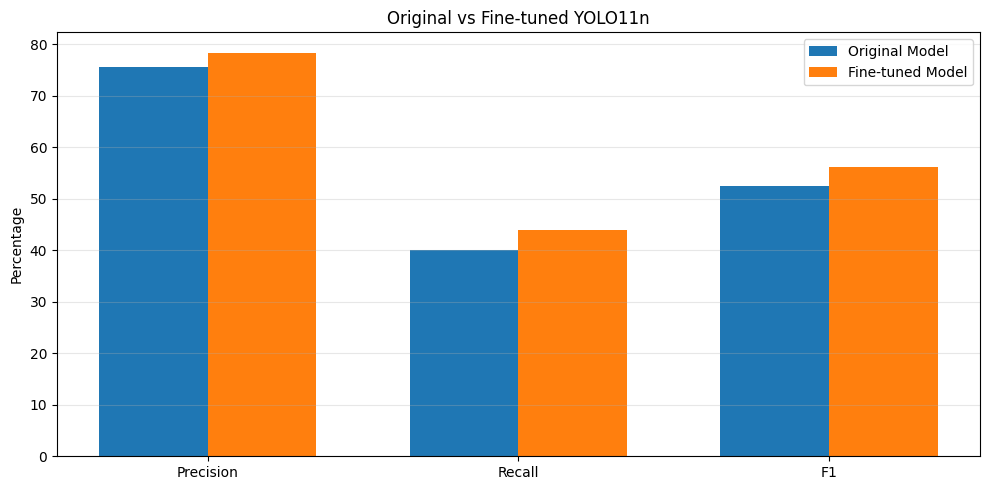

In [26]:
# ============================================================
# PERFORMANCE COMPARISON VISUALISATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

labels = ["Precision", "Recall", "F1"]

original_values = [
    baseline_val_summary["precision"],
    baseline_val_summary["recall"],
    baseline_val_summary["F1"]
]

finetuned_values = [
    ft_val_summary["precision"],
    ft_val_summary["recall"],
    ft_val_summary["F1"]
]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    np.array(original_values) * 100,
    width,
    label="Original Model"
)

plt.bar(
    x + width/2,
    np.array(finetuned_values) * 100,
    width,
    label="Fine-tuned Model"
)

plt.xticks(x, labels)
plt.ylabel("Percentage")
plt.title("Original vs Fine-tuned YOLO11n")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

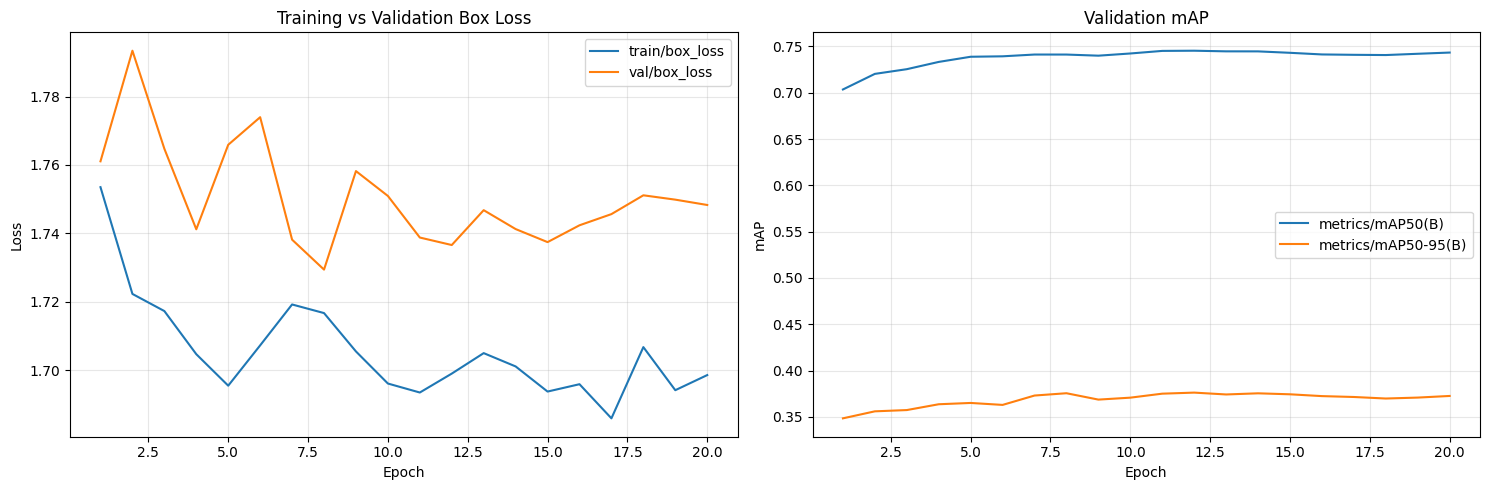

Best epoch: 12
Best validation mAP50-95: 0.37613
Last validation mAP50-95: 0.37252

NOTE: Validation mAP peaked more than five epochs before training ended. Inspect for overfitting.


In [27]:
# ============================================================
# OVERFITTING ANALYSIS
# ============================================================

history_path = FINETUNE_RUN_DIR / "results.csv"

assert history_path.exists(), "Training history not found!"

history_ft = pd.read_csv(history_path)
history_ft.columns = history_ft.columns.str.strip()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Training and validation box loss
for col in ["train/box_loss", "val/box_loss"]:

    if col in history_ft.columns:

        axes[0].plot(
            history_ft["epoch"],
            history_ft[col],
            label=col
        )

axes[0].set_title("Training vs Validation Box Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Validation mAP
for col in [
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]:

    if col in history_ft.columns:

        axes[1].plot(
            history_ft["epoch"],
            history_ft[col],
            label=col
        )

axes[1].set_title("Validation mAP")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mAP")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Identify best validation epoch
map_col = "metrics/mAP50-95(B)"

if map_col in history_ft.columns:

    best_epoch_idx = history_ft[map_col].idxmax()

    print("Best epoch:", int(history_ft.loc[best_epoch_idx, "epoch"]))
    print("Best validation mAP50-95:",
          history_ft.loc[best_epoch_idx, map_col])

    print("Last validation mAP50-95:",
          history_ft[map_col].iloc[-1])

    if best_epoch_idx < len(history_ft) - 5:
        print(
            "\nNOTE: Validation mAP peaked more than five epochs "
            "before training ended. Inspect for overfitting."
        )
    else:
        print("\nNo strong late-epoch mAP deterioration detected.")

In [28]:
# ============================================================
# CRATER SIZE-WISE VALIDATION COMPARISON
# ============================================================

def size_metrics(model, prediction_cache, conf):

    rows = []

    for rec in val_records:

        _, gt_all = coco_gt_for_image(
            "val",
            rec["image_id"]
        )

        gt = [
            g for g in gt_all
            if g["diam_m"] >= MIN_DIAMETER_M
        ]

        preds = [
            p for p in prediction_cache[rec["image_id"]]
            if p["conf"] >= conf
        ]

        matched = match_one_image(
            preds,
            gt_all,
            rec["resolution_m"],
            MIN_DIAMETER_M
        )

        # Reconstruct individual matches for size-wise recall
        scored = [
            g for g in gt_all
            if g["diam_m"] >= MIN_DIAMETER_M
        ]

        from scipy.optimize import linear_sum_assignment

        cost = np.full(
            (len(scored), len(preds)),
            1e6,
            dtype=float
        )

        valid = np.zeros_like(cost, dtype=bool)

        for i, g in enumerate(scored):

            for j, p in enumerate(preds):

                distance = np.hypot(
                    p["cx"] - g["cx"],
                    p["cy"] - g["cy"]
                )

                diameter_error = abs(
                    p["diam_px"] - g["diam_px"]
                ) / max(g["diam_px"], 1e-9)

                if (
                    distance <= 0.5 * g["diam_px"]
                    and diameter_error <= 0.5
                ):

                    valid[i, j] = True
                    cost[i, j] = distance + diameter_error

        if len(scored) and len(preds):

            ri, ci = linear_sum_assignment(cost)

            matches = [
                (i, j)
                for i, j in zip(ri, ci)
                if valid[i, j]
            ]

        else:
            matches = []

        matched_gt = {i for i, j in matches}

        for i, g in enumerate(scored):

            diameter = g["diam_m"]

            if diameter < 20:
                category = "10–20 m"
            elif diameter < 50:
                category = "20–50 m"
            elif diameter < 100:
                category = "50–100 m"
            else:
                category = "100+ m"

            rows.append({
                "size": category,
                "detected": int(i in matched_gt),
                "total": 1
            })

    df = pd.DataFrame(rows)

    report = df.groupby("size").agg(
        detected=("detected", "sum"),
        total=("total", "sum")
    ).reset_index()

    report["recall"] = (
        report["detected"] / report["total"]
    )

    return report


size_original = size_metrics(
    val_model,
    val_prediction_cache,
    BASELINE_CONF
)

size_finetuned = size_metrics(
    finetuned_eval_model,
    val_prediction_cache_ft,
    FINETUNED_CONF
)

size_comparison = size_original.merge(
    size_finetuned,
    on="size",
    suffixes=("_original", "_finetuned")
)

size_comparison["improvement"] = (
    size_comparison["recall_finetuned"] -
    size_comparison["recall_original"]
)

display(size_comparison)

size_comparison.to_csv(
    WORK / "crater_size_comparison.csv",
    index=False
)

,size,detected_original,total_original,recall_original,detected_finetuned,total_finetuned,recall_finetuned,improvement
0,100+ m,7,27,0.259259,11,27,0.407407,0.148148
1,10–20 m,429,597,0.718593,463,597,0.775544,0.056951
2,20–50 m,137,765,0.179085,152,765,0.198693,0.019608
3,50–100 m,14,75,0.186667,16,75,0.213333,0.026667


In [29]:
# ============================================================
# SAVE FINE-TUNED EXPERIMENT ARTIFACTS
# ============================================================

FINAL_EXPERIMENT_DIR = WORK / "finetuned_experiment_v1"

FINAL_EXPERIMENT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save fine-tuned model
shutil.copy2(
    FINETUNED_WEIGHTS,
    FINAL_EXPERIMENT_DIR / "best_finetuned_crater_model.pt"
)

# Save training history
shutil.copy2(
    history_path,
    FINAL_EXPERIMENT_DIR / "training_history.csv"
)

# Save comparison tables
comparison_ft.to_csv(
    FINAL_EXPERIMENT_DIR / "model_comparison.csv",
    index=False
)

size_comparison.to_csv(
    FINAL_EXPERIMENT_DIR / "crater_size_comparison.csv",
    index=False
)

# Save experiment metadata
experiment_info = {
    "baseline_checkpoint": str(BASELINE_WEIGHTS),
    "finetuned_checkpoint": str(FINETUNED_WEIGHTS),
    "learning_rate": FINETUNE_LR,
    "epochs_requested": FINETUNE_EPOCHS,
    "patience": FINETUNE_PATIENCE,
    "image_size": 640,
    "baseline_confidence": BASELINE_CONF,
    "finetuned_confidence": FINETUNED_CONF,
    "baseline_validation": baseline_val_summary,
    "finetuned_validation": ft_val_summary
}

with open(
    FINAL_EXPERIMENT_DIR / "experiment_metadata.json",
    "w"
) as f:
    json.dump(experiment_info, f, indent=4)

print("Experiment saved successfully!")
print(FINAL_EXPERIMENT_DIR)

Experiment saved successfully!
/kaggle/working/crater_yolo_work_fresh_v2/finetuned_experiment_v1


In [30]:

from pathlib import Path
import shutil
from IPython.display import FileLink, display

source = Path(WORK) / "best_crater_model_fresh_v2.pt"
destination = Path("/kaggle/working/best_crater_model_fresh_v2.pt")

shutil.copy2(source, destination)

print("Checkpoint ready!")
display(FileLink(str(destination)))


Checkpoint ready!


/kaggle/working/best_crater_model_fresh_v2.pt

In [31]:

import os
import shutil
from IPython.display import FileLink, display

# Output ZIP file
zip_name = "/kaggle/working/all_outputs"

# Source directory containing generated outputs
source_dir = "/kaggle/working"

# Create ZIP archive
shutil.make_archive(
    zip_name,
    'zip',
    source_dir
)

# Display download link
zip_path = zip_name + ".zip"

print(f"All outputs successfully compiled!")
print(f"ZIP file size: {os.path.getsize(zip_path) / (1024**2):.2f} MB")

display(FileLink(zip_path))


All outputs successfully compiled!
ZIP file size: 210.29 MB


/kaggle/working/all_outputs.zip